# 统计学习导论作业 3：概率生成式分类

姓名：咸蛋超人迪卡　班级：统计　学号：114514

本文使用 58,509 条电机电流特征记录，推导并实现高斯生成分类、高斯朴素贝叶斯与离散朴素贝叶斯；展示先验、似然、证据、后验以及每一类的决策分数，比较协方差约束、平滑和 KNN 距离投票对识别效果的影响。

全文按“理论推导 → 数据与估计 → 逐类概率复算 → 图形解释 → 调参优化 → 独立测试”展开。公式中的参数会在真实训练集上逐一计算，并用数值结果与 scikit-learn 实现互相校验。

## 一、数据与实验设计

### 1.1 数据来源

数据来自 UCI 的 [Dataset for Sensorless Drive Diagnosis](https://archive.ics.uci.edu/dataset/325/dataset+for+sensorless+drive+diagnosis)，创建者 Martyna Bator。原始文件为 `data/Sensorless_drive_diagnosis.txt`，共 58,509 行、49 列：前 48 列为实数特征，末列为状态编号 1—11，每类 5,319 条记录。

UCI 说明这些特征从两相电流信号经经验模态分解（EMD）和子序列统计得到，涉及均值、标准差、偏度、峰度。观测覆盖完整和损坏组件，以及不同转速、负载力矩和负载力的工况。公开文件以位置存储特征，本文统一使用 `F01`—`F48` 和 `C01`—`C11` 标识列与类别。

设训练数据为 $\mathcal D=\{(x_i,y_i)\}_{i=1}^{n}$，$x_i\in\mathbb R^{d}$，$d=48$；类别数 $K=11$。$n_k=\sum_i\mathbf1(y_i=k)$，$\pi_k=P(Y=k)$。本作业评估同一公开记录总体中随机留出样本的识别表现。原始文件未附逐行试验批次和电机编号，按独立电机或完整工况外推的评估需要相应分组标识。

### 1.2 数据划分

分层划分约 60% 训练、20% 验证、20% 测试。训练集内部固定抽取 12,000 条分层样本，以三折交叉验证初筛全部参数组合；每个模型的前三组参数再放到**完整训练集进行三折交叉验证**，确定最终参数。两阶段设计先控制搜索成本，再检查参数对训练规模的适应性。随后每个模型在完整训练集重拟合，以完整验证集的宏平均 F1 选模型族，分数相同时依次比较 Log Loss、模型名。最后固定所选模型与参数，用训练+验证集合并数据重拟合，再评估测试集。

同一初筛子样本和相同交叉验证折用于全部模型，预处理在 Pipeline 内按折拟合。完整训练集精筛同样共享折划分；两阶段的参数按交叉验证宏F1降序、Log Loss升序排列。测试标签只在最终评估和误差分析阶段使用。最终参数属于本次给定搜索范围内的选择。

In [1]:
from pathlib import Path
import hashlib
import json
import time
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy.special import logsumexp
from scipy.stats import multivariate_normal, norm
import sklearn
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, KBinsDiscretizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, f1_score, log_loss, classification_report,
                             confusion_matrix, roc_auc_score, roc_curve, recall_score)
from threadpoolctl import threadpool_limits
from IPython.display import display, Markdown, Math, HTML

# 防止多个数值库争用全部处理器；结果随机性由固定种子控制。
thread_limit = threadpool_limits(limits=4)
SEED = 114514
plt.rcParams.update({
    'font.sans-serif': ['Microsoft YaHei', 'SimHei', 'DejaVu Sans'],
    'axes.unicode_minus': False, 'figure.dpi': 130, 'savefig.dpi': 160,
    'axes.spines.top': False, 'axes.spines.right': False,
})
COLORS = sns.color_palette('tab20', 11)
ROOT = Path.cwd()
if not (ROOT / 'data/Sensorless_drive_diagnosis.txt').exists():
    ROOT = ROOT / 'homework3_generative_bayes'
DATA_PATH = ROOT / 'data/Sensorless_drive_diagnosis.txt'

def show_figure(name):
    # 图表直接嵌入 notebook。
    plt.show()

def show_table_details(table, title):
    # 长表折叠展示，保留完整计算明细，便于逐项核对。
    html = '<details><summary>' + title + '</summary>'
    html += table.to_html(index=False, float_format=lambda x: f'{x:.7g}')
    display(HTML(html + '</details>'))

features = [f'F{i:02d}' for i in range(1, 49)]
data = pd.read_csv(DATA_PATH, sep=r'\s+', header=None, names=features + ['class'])
X = data[features].astype(float)
y = data['class'].astype(int)
classes = np.sort(y.unique())
class_names = [f'C{k:02d}' for k in classes]
assert X.shape == (58509, 48) and np.isfinite(X.to_numpy()).all()
assert len(classes) == 11 and set(y.unique()) == set(range(1, 12))
print(f'观测数={len(data):,}，特征数={X.shape[1]}，类别数={len(classes)}')
print('缺失值=', data.isna().sum().sum(), '完全重复记录=', data.duplicated().sum())
print('原始数据 SHA256：', hashlib.sha256(DATA_PATH.read_bytes()).hexdigest())
display(data.head(6))
display(y.value_counts().sort_index().rename('样本数').to_frame().T)

trainval_idx, test_idx = train_test_split(
    np.arange(len(data)), test_size=.20, random_state=SEED, stratify=y)
train_idx, val_idx = train_test_split(
    trainval_idx, test_size=.25, random_state=SEED, stratify=y.iloc[trainval_idx])
tune_idx, _ = train_test_split(
    train_idx, train_size=12000, random_state=SEED, stratify=y.iloc[train_idx])
X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]
X_tune, y_tune = X.iloc[tune_idx], y.iloc[tune_idx]
assert set(train_idx).isdisjoint(val_idx) and set(train_idx).isdisjoint(test_idx)
assert set(val_idx).isdisjoint(test_idx) and set(tune_idx).issubset(train_idx)
split_table = pd.DataFrame({
    '训练': y_train.value_counts().sort_index(),
    '验证': y_val.value_counts().sort_index(),
    '测试': y_test.value_counts().sort_index(),
    '训练内调参': y_tune.value_counts().sort_index(),
})
display(split_table)
print('训练/验证/测试：', len(train_idx), len(val_idx), len(test_idx))

观测数=58,509，特征数=48，类别数=11
缺失值= 0 完全重复记录= 0


原始数据 SHA256： 366b8c5c564a5a4d07600db9180d2871f51489104b554f6320781514059f35a9


,F01,F02,F03,F04,F05,F06,F07,F08,F09,F10,...,F40,F41,F42,F43,F44,F45,F46,F47,F48,class
0,-3.014600e-07,8.260300e-06,-0.000012,-2.309800e-06,-1.438600e-06,-0.000021,0.031718,0.031710,0.031721,-0.032963,...,-0.63308,2.9646,8.1198,-1.4961,-1.4961,-1.4961,-1.4996,-1.4996,-1.4996,1
1,2.913200e-06,-5.247700e-06,0.000003,-6.056100e-06,2.778900e-06,-0.000004,0.030804,0.030810,0.030806,-0.033520,...,-0.59314,7.6252,6.1690,-1.4967,-1.4967,-1.4967,-1.5005,-1.5005,-1.5005,1
2,-2.951700e-06,-3.184000e-06,-0.000016,-1.208400e-06,-1.575300e-06,0.000017,0.032877,0.032880,0.032896,-0.029834,...,-0.63252,2.7784,5.3017,-1.4983,-1.4983,-1.4982,-1.4985,-1.4985,-1.4985,1
3,-1.322600e-06,8.820100e-06,-0.000016,-4.811100e-06,-7.282900e-07,0.000004,0.029410,0.029401,0.029417,-0.030156,...,-0.62289,6.5534,6.2606,-1.4963,-1.4963,-1.4963,-1.4975,-1.4975,-1.4976,1
4,-6.836600e-08,5.666300e-07,-0.000026,-6.490100e-06,-7.940600e-07,0.000013,0.030119,0.030119,0.030145,-0.031393,...,-0.63010,4.5155,9.5231,-1.4958,-1.4958,-1.4958,-1.4959,-1.4959,-1.4959,1
5,-9.584900e-07,5.214300e-08,-0.000047,6.453700e-07,-2.304100e-06,0.000055,0.031154,0.031154,0.031201,-0.032789,...,-0.61124,5.8337,18.6970,-1.4956,-1.4956,-1.4956,-1.4973,-1.4972,-1.4973,1


class,1,2,3,4,5,6,7,8,9,10,11
样本数,5319,5319,5319,5319,5319,5319,5319,5319,5319,5319,5319


,训练,验证,测试,训练内调参
class,,,,
1,3191,1064,1064,1091
2,3191,1064,1064,1091
3,3192,1064,1063,1091
4,3191,1064,1064,1091
5,3191,1064,1064,1090
6,3191,1064,1064,1091
7,3191,1064,1064,1091
8,3192,1063,1064,1091
9,3191,1064,1064,1091


训练/验证/测试： 35105 11702 11702


### 1.3 数据特征分析

GaussianNB 的平滑量和 KNN 的距离都受量纲影响，先查看每列标准差。相关热图分别计算训练集总体相关和类别 C01 内相关。朴素贝叶斯要求的是 **给定类别后特征条件独立**，因此类内相关尤其值得检查；高斯条件独立模型对应对角协方差。全协方差模型将非对角元素用于密度计算。

下文用于数值复算的标准化器仅在训练集拟合。可视化保留原始数据的全部记录用于统计，散点绘制采用固定随机种子的子样本，模型训练仍按上述完整划分执行。

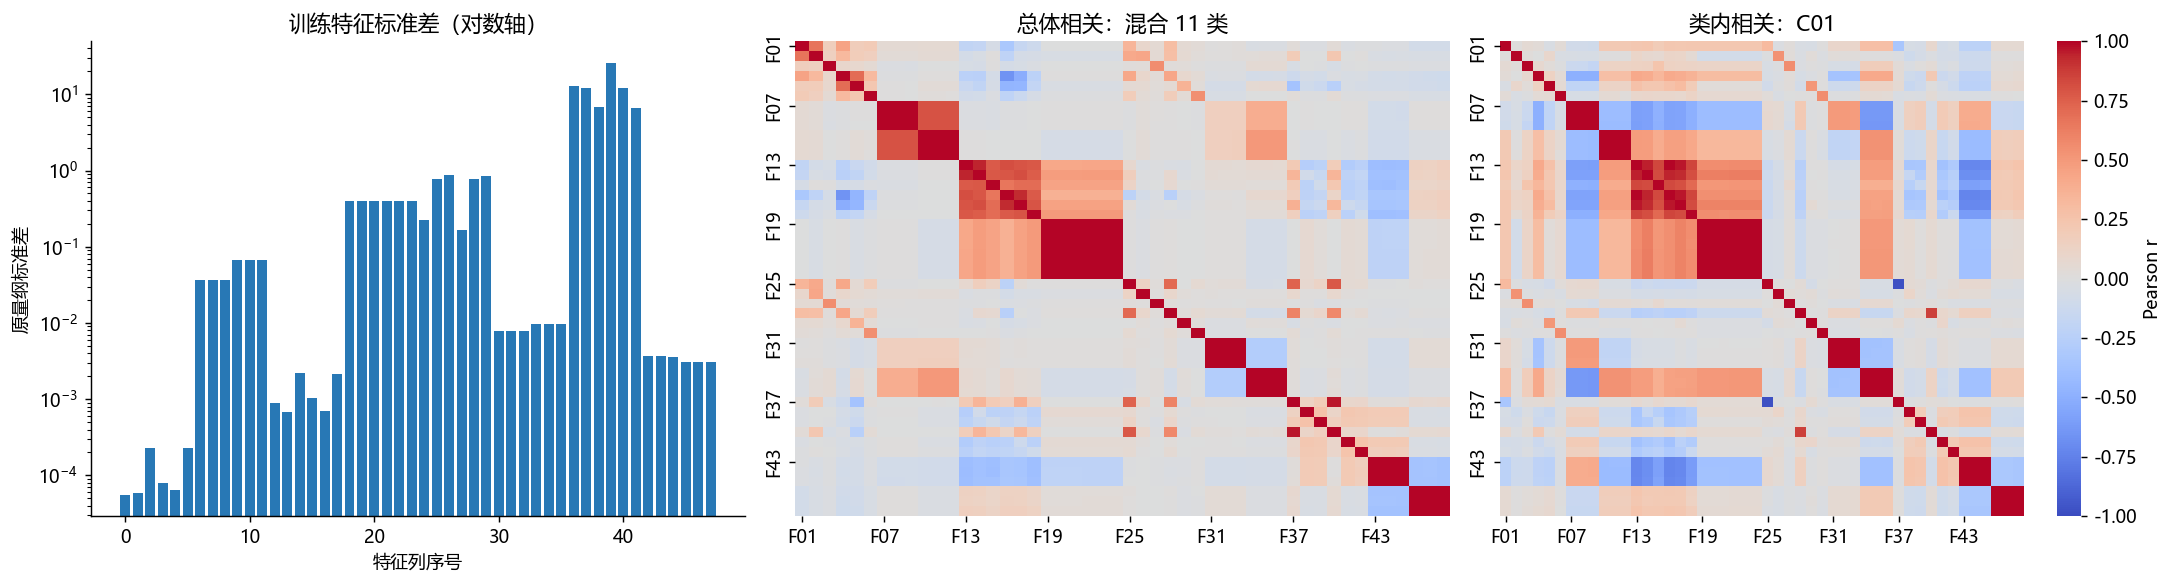

In [2]:
manual_scaler = StandardScaler().fit(X_train)
Z_train = manual_scaler.transform(X_train)
Z_val = manual_scaler.transform(X_val)
Z_test = None  # 测试特征的最终模型预测集中放在最后一节。
stds = X_train.std(ddof=0)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
axes[0].bar(np.arange(48), stds, color='#2878B5')
axes[0].set(yscale='log', title='训练特征标准差（对数轴）', xlabel='特征列序号', ylabel='原量纲标准差')
sns.heatmap(X_train.corr(), vmin=-1, vmax=1, cmap='coolwarm', ax=axes[1],
            xticklabels=6, yticklabels=6, cbar=False)
axes[1].set_title('总体相关：混合 11 类')
sns.heatmap(X_train.loc[y_train == 1].corr(), vmin=-1, vmax=1, cmap='coolwarm',
            ax=axes[2], xticklabels=6, yticklabels=6, cbar_kws={'label': 'Pearson r'})
axes[2].set_title('类内相关：C01')
plt.tight_layout()
show_figure('01_scale_and_conditional_correlation')

## 二、贝叶斯分类

### 2.1 贝叶斯决策

生成式分类先建模 $p(x,Y=k)=\pi_k f_k(x)$，其中 $f_k(x)=p(x\mid Y=k)$。全概率公式给出证据（边缘密度）：

$$p(x)=\sum_{r=1}^{K}\pi_r f_r(x).$$

因此对每一个类别都有

$$\gamma_k(x)=P(Y=k\mid X=x)=\frac{\pi_k f_k(x)}{\sum_{r=1}^{K}\pi_r f_r(x)},\qquad \sum_{k=1}^{K}\gamma_k(x)=1.$$

连续特征使用**密度** $f_k(x)$，其积分为 1；区间概率由积分给出。所有类别在同一坐标和同一观测 $x$ 下比较，统一的单位变换在后验归一化时抵消。

若正确分类损失为 0、误分类损失为 1，则预测类别 $a$ 的条件风险为

$$R(a\mid x)=\sum_{k=1}^{K}\mathbf1(a\ne k)\gamma_k(x)=1-\gamma_a(x).$$

最小化该风险得到最大后验（MAP）分类：$\hat y=\arg\max_k\gamma_k(x)=\arg\max_k[\log\pi_k+\log f_k(x)]$。若误判代价由矩阵 $L(a,k)$ 指定，规则改为 $\arg\min_a\sum_k L(a,k)\gamma_k(x)$。本作业各类使用等误判代价。

### 2.2 课件例题

第 15 页给出 $P(B_1)=2/3$、$P(B_2)=1/3$，$P(Blue\mid B_1)=4/5$、$P(Blue\mid B_2)=2/5$。观测蓝球后，$P(Blue)=\frac23\frac45+\frac13\frac25=\frac23$；因此 $P(B_1\mid Blue)=\frac{8/15}{10/15}=0.8$，$P(B_2\mid Blue)=0.2$。这个计算顺序在后文扩展为 11 类真实数据。

In [3]:
box_prior = np.array([2/3, 1/3])
blue_likelihood = np.array([4/5, 2/5])
box_joint = box_prior * blue_likelihood
box_evidence = box_joint.sum()
box_posterior = box_joint / box_evidence
display(pd.DataFrame({'先验': box_prior, '蓝球条件概率': blue_likelihood,
                      '联合概率': box_joint, '后验': box_posterior}, index=['B1', 'B2']))
print(f'证据 P(Blue)={box_evidence:.6f}，后验和={box_posterior.sum():.6f}')

,先验,蓝球条件概率,联合概率,后验
B1,0.666667,0.8,0.533333,0.8
B2,0.333333,0.4,0.133333,0.2


证据 P(Blue)=0.666667，后验和=1.000000


## 三、高斯生成模型

### 3.1 极大似然估计

本文的连续生成模型采用**参数的极大似然估计和类别的贝叶斯后验分类**：先用训练样本估计 $\pi_k,\mu_k,\Sigma_k$，再将估计值代入 $P(Y=k\mid x)$。第六节为离散条件概率指定 Dirichlet 参数先验，并使用其后验预测概率。$P(Y=k)$ 描述类别比例，参数先验 $p(\theta)$ 描述对未知参数的分布假设，两者在推导中分别记号。

假设样本在给定参数下独立，$X\mid Y=k\sim N_d(\mu_k,\Sigma_k)$，$\Sigma_k\succ0$。联合似然和对数似然为

$$L(\pi,\mu,\Sigma)=\prod_{i=1}^{n}\pi_{y_i}(2\pi)^{-d/2}|\Sigma_{y_i}|^{-1/2}
\exp\!\left[-\frac12(x_i-\mu_{y_i})^\top\Sigma_{y_i}^{-1}(x_i-\mu_{y_i})\right],$$

$$\ell=\sum_k n_k\log\pi_k-\frac{nd}{2}\log(2\pi)-\frac12\sum_k\left[n_k\log|\Sigma_k|+
\sum_{i:y_i=k}(x_i-\mu_k)^\top\Sigma_k^{-1}(x_i-\mu_k)\right].$$

约束 $\sum_k\pi_k=1$，引入 $\lambda(\sum_k\pi_k-1)$，求导得到 $n_k/\pi_k+\lambda=0$，求和得 $\lambda=-n$，于是 $\hat\pi_k=n_k/n$。

对均值求导：$\partial\ell/\partial\mu_k=\Sigma_k^{-1}\sum_{i:y_i=k}(x_i-\mu_k)=0$，因此

$$\hat\mu_k=\frac1{n_k}\sum_{i:y_i=k}x_i.$$

令精度矩阵 $A_k=\Sigma_k^{-1}$，$S_k=\sum_{i:y_i=k}(x_i-\hat\mu_k)(x_i-\hat\mu_k)^\top$，则与该类协方差有关的对数似然为
$\ell_k=\frac{n_k}{2}\log|A_k|-\frac12\operatorname{tr}(A_kS_k)+\text{常数}$。
由 $\partial\log|A|/\partial A=A^{-\top}$，有 $\frac{n_k}{2}A_k^{-\top}-\frac12S_k^\top=0$，从而

$$\hat\Sigma_k=\frac{S_k}{n_k}=\frac1{n_k}\sum_{i:y_i=k}(x_i-\hat\mu_k)(x_i-\hat\mu_k)^\top.$$

这是极大似然协方差，分母取 $n_k$；无偏样本协方差分母取 $n_k-1$。手工推导统一使用 MLE，后文对 GaussianNB 做精确复核；sklearn QDA 的类协方差基于 $n_k-1$，其正则化实现另列说明。

### 3.2 LDA 与 QDA

加入 $\Sigma_1=\cdots=\Sigma_K=\Sigma$ 后，对所有类的散度一起求导，得

$$\hat\Sigma=\frac1n\sum_k\sum_{i:y_i=k}(x_i-\hat\mu_k)(x_i-\hat\mu_k)^\top
=\sum_k\frac{n_k}{n}\hat\Sigma_k.$$

单类对数联合密度为 $g_k(x)=\log\pi_k-\frac d2\log(2\pi)-\frac12\log|\Sigma_k|-\frac12(x-\mu_k)^\top\Sigma_k^{-1}(x-\mu_k)$。
QDA 保留类别特异的 $\Sigma_k$。展开任意两类的对数后验比，归一化证据在比值中抵消：

$$\log\frac{P(Y=a\mid x)}{P(Y=b\mid x)}=g_a(x)-g_b(x)=x^\top A_{ab}x+b_{ab}^\top x+c_{ab},$$

$$A_{ab}=-\frac12(\Sigma_a^{-1}-\Sigma_b^{-1}),\qquad b_{ab}=\Sigma_a^{-1}\mu_a-\Sigma_b^{-1}\mu_b,$$

$$c_{ab}=\log\frac{\pi_a}{\pi_b}-\frac12\log\frac{|\Sigma_a|}{|\Sigma_b|}
-\frac12\mu_a^\top\Sigma_a^{-1}\mu_a+\frac12\mu_b^\top\Sigma_b^{-1}\mu_b.$$

零一损失下两类分界满足该式为零，因此其二次项来自逆协方差之差。共享 $\Sigma$ 时，$A_{ab}=0$，$x^\top\Sigma^{-1}x$ 在类间比较中抵消，得到

$$\delta_k(x)=x^\top\Sigma^{-1}\mu_k-\frac12\mu_k^\top\Sigma^{-1}\mu_k+\log\pi_k,$$

即 LDA 的线性判别函数。二分类中

$$P(Y=a\mid x)=\frac1{1+e^{-z}},\quad z=\delta_a(x)-\delta_b(x)=w^\top x+b,$$

$$w=\Sigma^{-1}(\mu_a-\mu_b),\quad
b=-\frac12\mu_a^\top\Sigma^{-1}\mu_a+\frac12\mu_b^\top\Sigma^{-1}\mu_b+\log\frac{\pi_a}{\pi_b}.$$

这一推导将课件第 34—40 页的后验、密度比和线性边界连接起来。多分类则用 $\gamma_k=\exp(g_k)/\sum_r\exp(g_r)$ 统一归一化。

### 3.3 高斯朴素贝叶斯

朴素贝叶斯施加条件独立假设：$p(x\mid Y=k)=\prod_{j=1}^{d}p(x_j\mid Y=k)$。若每维条件分布为 $N(\mu_{kj},\sigma_{kj}^2)$，协方差矩阵是对角阵，估计量为

$$\hat\mu_{kj}=\frac1{n_k}\sum_{i:y_i=k}x_{ij},\qquad
\hat\sigma_{kj}^2=\frac1{n_k}\sum_{i:y_i=k}(x_{ij}-\hat\mu_{kj})^2.$$

scikit-learn `GaussianNB` 的方差平滑是在每个类、每个特征的方差上增加相同的训练数据相关常数：

$$\epsilon=\texttt{var\_smoothing}\times\max_j\operatorname{Var}_{train}(X_j),\qquad v_{kj}=\hat\sigma_{kj}^2+\epsilon.$$

因此小方差特征的密度峰得到限制，取对数时也得到稳定的正分母。本作业先标准化，便于在一致尺度上调平滑强度。概率计算写成

$$g_k(x)=\log\hat\pi_k-\frac12\sum_{j=1}^{d}\left[\log(2\pi v_{kj})+\frac{(x_j-\hat\mu_{kj})^2}{v_{kj}}\right].$$

令 $m=\max_k g_k(x)$，则 $\log p(x)=m+\log\sum_k e^{g_k(x)-m}$，$\gamma_k=e^{g_k-\log p(x)}$。`logsumexp` 实现这一归一化，避免 48 个小密度相乘造成浮点下溢。

参数个数体现协方差约束的作用：先验有 $K-1$ 个自由度；GNB 共 $2Kd+K-1$ 个，LDA 共 $Kd+d(d+1)/2+K-1$ 个，QDA 共 $Kd+Kd(d+1)/2+K-1$ 个。

In [4]:
# 从训练数据自行估计参数；GaussianNB 只用于后续核对。
n_train, d = Z_train.shape
K = len(classes)
counts = np.array([(y_train.to_numpy() == k).sum() for k in classes])
priors = counts / n_train
means, mle_variances, mle_covariances = [], [], []
for k in classes:
    z_k = Z_train[y_train.to_numpy() == k]
    mu_k = z_k.mean(axis=0)
    centered = z_k - mu_k
    means.append(mu_k)
    mle_variances.append(np.mean(centered**2, axis=0))
    mle_covariances.append(centered.T @ centered / len(z_k))
means = np.asarray(means)
mle_variances = np.asarray(mle_variances)
mle_covariances = np.asarray(mle_covariances)
pooled_cov = np.einsum('k,kij->ij', priors, mle_covariances)
smooth = 1e-9
epsilon = smooth * np.var(Z_train, axis=0).max()
stable_vars = mle_variances + epsilon

parameter_table = pd.DataFrame({
    '类别': np.repeat(class_names, d), '训练样本数': np.repeat(counts, d),
    '特征': np.tile(features, K), '均值_MLE': means.ravel(),
    '方差_MLE': mle_variances.ravel(), '平滑后方差': stable_vars.ravel(),
})
prior_table = pd.DataFrame({'类别': class_names, 'n_k': counts, 'n': n_train, '先验_nk/n': priors})
display(prior_table)
display(parameter_table.head(16))
show_table_details(parameter_table, '展开完整 11×48 组高斯均值和方差')
display(pd.DataFrame({'模型': ['GNB', 'LDA', 'QDA'], '参数自由度': [
    2*K*d + K-1, K*d+d*(d+1)//2+K-1, K*d+K*d*(d+1)//2+K-1]}))

def manual_gnb_scores(z):
    # 对每行、每类、每维直接计算高斯对数密度，再加对数先验。
    z = np.atleast_2d(z)
    feature_terms = -.5*(np.log(2*np.pi*stable_vars)[None, :, :]
                        + (z[:, None, :] - means[None, :, :])**2 / stable_vars[None, :, :])
    scores = np.log(priors)[None, :] + feature_terms.sum(axis=2)
    probability = np.exp(scores - logsumexp(scores, axis=1, keepdims=True))
    return feature_terms, scores, probability

gnb_reference = GaussianNB(var_smoothing=smooth).fit(Z_train, y_train)
np.testing.assert_allclose(means, gnb_reference.theta_, atol=1e-12)
np.testing.assert_allclose(stable_vars, gnb_reference.var_, atol=1e-12)
_, _, manual_prob_20 = manual_gnb_scores(Z_val[:20])
np.testing.assert_allclose(manual_prob_20, gnb_reference.predict_proba(Z_val[:20]), atol=1e-10)
print('核验通过：手算均值、方差与前 20 条验证记录的 11 类后验，与 sklearn 一致。')

,类别,n_k,n,先验_nk/n
0,C01,3191,35105,0.090899
1,C02,3191,35105,0.090899
2,C03,3192,35105,0.090927
3,C04,3191,35105,0.090899
4,C05,3191,35105,0.090899
5,C06,3191,35105,0.090899
6,C07,3191,35105,0.090899
7,C08,3192,35105,0.090927
8,C09,3191,35105,0.090899
9,C10,3192,35105,0.090927


,类别,训练样本数,特征,均值_MLE,方差_MLE,平滑后方差
0,C01,3191,F01,0.031776,0.022819,0.022819
1,C01,3191,F02,0.199022,0.461234,0.461234
2,C01,3191,F03,0.141551,0.969881,0.969881
3,C01,3191,F04,0.017344,0.010456,0.010456
4,C01,3191,F05,0.261898,0.291348,0.291348
5,C01,3191,F06,0.106545,0.949895,0.949895
6,C01,3191,F07,0.575106,0.023714,0.023714
7,C01,3191,F08,0.574815,0.023732,0.023732
8,C01,3191,F09,0.573850,0.024018,0.024018
9,C01,3191,F10,-0.332452,0.014531,0.014531


类别,训练样本数,特征,均值_MLE,方差_MLE,平滑后方差
C01,3191,F01,0.03177603,0.02281901,0.02281901
C01,3191,F02,0.1990217,0.4612336,0.4612336
C01,3191,F03,0.1415515,0.9698807,0.9698807
C01,3191,F04,0.01734414,0.0104565,0.0104565
C01,3191,F05,0.2618978,0.2913479,0.2913479
C01,3191,F06,0.1065452,0.9498951,0.9498951
C01,3191,F07,0.5751061,0.02371366,0.02371366
C01,3191,F08,0.5748153,0.0237319,0.0237319
C01,3191,F09,0.5738497,0.02401771,0.02401771
C01,3191,F10,-0.3324523,0.01453092,0.01453092


,模型,参数自由度
0,GNB,1066
1,LDA,1714
2,QDA,13474


核验通过：手算均值、方差与前 20 条验证记录的 11 类后验，与 sklearn 一致。


### 3.4 参数计算

参数表中的每个数都对应训练记录的运算。以 C01 的 F01、F02 为例，下面列出样本和、中心平方和与中心交叉乘积和，并直接代入 $n_1$。均值使用一次和，方差使用二次中心矩，协方差使用两列的中心交叉矩。共享协方差再按各类先验加权。

In [5]:
z_c1 = Z_train[y_train.to_numpy() == classes[0]]
n1 = len(z_c1)
sum_z1, sum_z2 = z_c1[:, :2].sum(axis=0)
c1_centered = z_c1[:, :2] - z_c1[:, :2].mean(axis=0)
ss1 = np.sum(c1_centered[:, 0]**2)
cross12 = np.sum(c1_centered[:, 0]*c1_centered[:, 1])
display(Math(rf'\widehat\pi_1=\frac{{{n1}}}{{{n_train}}}={priors[0]:.9f}'))
display(Math(rf'\widehat\mu_{{1,1}}=\frac{{\sum_{{i:y_i=1}}z_{{i1}}}}{{n_1}}'
             rf'=\frac{{{sum_z1:.9f}}}{{{n1}}}={means[0,0]:.9f},\quad '
             rf'\widehat\mu_{{1,2}}=\frac{{{sum_z2:.9f}}}{{{n1}}}={means[0,1]:.9f}'))
display(Math(rf'\widehat\sigma_{{1,1}}^2=\frac{{{ss1:.9f}}}{{{n1}}}'
             rf'={mle_variances[0,0]:.9f},\quad v_{{1,1}}={mle_variances[0,0]:.9f}+{epsilon:.4g}'))
display(Math(rf'\widehat\Sigma_{{1,12}}=\frac{{{cross12:.9f}}}{{{n1}}}'
             rf'={mle_covariances[0,0,1]:.9f}'))
pooled_terms = priors*mle_covariances[:, 0, 1]
display(pd.DataFrame({'类别':class_names,'权重nk/n':priors,
                      '类内MLE协方差F01_F02':mle_covariances[:,0,1],
                      '加权贡献':pooled_terms}))
print(f'共享协方差 Σ[F01,F02] = 上表贡献之和 = {pooled_terms.sum():.9f}')
np.testing.assert_allclose(pooled_terms.sum(), pooled_cov[0,1])

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

,类别,权重nk/n,类内MLE协方差F01_F02,加权贡献
0,C01,0.090899,0.001023,0.000093
1,C02,0.090899,4.622567,0.420185
2,C03,0.090927,0.004696,0.000427
3,C04,0.090899,0.010650,0.000968
4,C05,0.090899,2.488796,0.226228
5,C06,0.090899,0.046043,0.004185
6,C07,0.090899,0.048199,0.004381
7,C08,0.090927,0.014578,0.001326
8,C09,0.090899,0.016581,0.001507
9,C10,0.090927,0.010006,0.000910


共享协方差 Σ[F01,F02] = 上表贡献之和 = 0.661994818


## 四、后验概率计算

### 4.1 单样本计算

选取验证集排列中的第一条记录，选择规则预先固定。原始观测先按训练均值、标准差变换为 $z_j=(x_j-\bar x_{train,j})/s_{train,j}$。下表给出全部 48 个输入及标准化值；随后计算所有 $11\times48$ 个条件对数密度。

对每个类，分别列出 $\log\pi_k$、$\log f_k(z)$、$g_k=\log\pi_k+\log f_k(z)$、联合密度 $e^{g_k}$、证据 $\sum_r e^{g_r}$ 与后验。表中另列最大分数平移后的 $e^{g_k-m}$，保持后验比值不变。极小密度直接指数化可能触及浮点数下溢并显示为 0；对数密度和 $\log_{10}$ 后验保留这些数量级，实际计算始终先在对数域完成归一化。

In [6]:
example_position = 0
row_id = int(X_val.index[example_position])
z_example = Z_val[example_position]
feature_terms, example_scores, example_prob = manual_gnb_scores(z_example)
g = example_scores[0]
posterior = example_prob[0]
log_evidence = float(logsumexp(g))
likelihood_logs = feature_terms[0].sum(axis=1)
input_table = pd.DataFrame({
    '特征': features, '原始值': X_val.iloc[example_position].to_numpy(),
    '训练均值': manual_scaler.mean_, '训练标准差': manual_scaler.scale_,
    '标准化z': z_example,
})
with pd.option_context('display.max_rows', 60, 'display.float_format', '{:.6g}'.format):
    display(input_table)
contribution_table = pd.DataFrame(feature_terms[0].T, index=features, columns=class_names)
display(Markdown('**全部 48 维在 11 个类别下的对数密度贡献：**'))
with pd.option_context('display.max_rows', 60, 'display.max_columns', 12):
    display(contribution_table.round(3))
example_result = pd.DataFrame({
    '类别': class_names, 'log先验': np.log(priors), 'log类条件密度': likelihood_logs,
    'log联合密度g': g, '类条件密度f': np.exp(likelihood_logs),
    '联合密度prior*f': np.exp(g), '后验P(k|z)': posterior,
    'log10后验':(g-log_evidence)/np.log(10),
    '平移联合密度exp(g-m)': np.exp(g-g.max()),
})
display(example_result.style.format({col: '{:.7g}' for col in example_result.columns if col != '类别'}))
print(f'样本原始行号={row_id}，log证据={log_evidence:.8f}，证据={np.exp(log_evidence):.8g}')
print(f'最大后验预测=C{classes[np.argmax(posterior)]:02d}；实际标签=C{y_val.iloc[example_position]:02d}')
print('11 个后验之和：', posterior.sum())

# 将真实数值直接填入公式；每一个类均展示，指数形式保留非常小的后验。
for index, k in enumerate(classes):
    display(Math(rf'g_{{{k}}}={np.log(priors[index]):.6f}+({likelihood_logs[index]:.6f})={g[index]:.6f},'
                 rf'\quad P(C_{{{k}}}\mid z)=\exp[{g[index]:.6f}-({log_evidence:.6f})]'
                 rf'={posterior[index]:.6g}'))

# 另展开 C01 的 F01 单维密度，说明上方矩阵中每一格的来源。
j, kpos = 0, 0
mu, var, value = means[kpos, j], stable_vars[kpos, j], z_example[j]
display(Math(rf'\log f_{{1,1}}(z_1)=-\frac12\left[\log(2\pi\times{var:.7g})'
             rf'+\frac{{({value:.7g}-({mu:.7g}))^2}}{{{var:.7g}}}\right]'
             rf'={feature_terms[0,kpos,j]:.7g}'))

,特征,原始值,训练均值,训练标准差,标准化z
0,F01,-1.068e-06,-3.118e-06,5.60284e-05,0.0365886
1,F02,-1.2827e-06,1.66684e-06,5.92864e-05,-0.0497506
2,F03,-1.7374e-05,9.46469e-07,0.000229679,-0.0797657
3,F04,2.7697e-06,-1.57757e-06,7.99092e-05,0.0544027
4,F05,-5.2603e-06,1.29663e-06,6.4079e-05,-0.102326
5,F06,1.7449e-05,-5.84231e-07,0.000229636,0.0785296
6,F07,0.035931,0.00192266,0.0364987,0.93177
7,F08,0.035932,0.001921,0.0364966,0.931895
8,F09,0.035949,0.00192005,0.0365014,0.932265
9,F10,0.0068645,-0.0119213,0.0664405,0.282746


**全部 48 维在 11 个类别下的对数密度贡献：**

,C01,C02,C03,C04,C05,C06,C07,C08,C09,C10,C11
F01,0.971,-1.918,1.028,1.009,-1.526,0.727,0.775,0.937,0.668,1.032,0.172
F02,-0.599,-1.643,-0.588,-0.683,-1.323,-0.589,-0.597,-0.550,-0.583,-0.550,-0.458
F03,-0.929,-1.113,-0.902,-0.866,-0.878,-0.902,-0.809,-0.926,-0.932,-0.972,-0.849
F04,1.296,-1.440,1.308,1.024,1.054,-1.961,1.337,0.700,1.047,1.345,1.126
F05,-0.530,-0.808,-0.500,-0.435,-0.395,-1.793,-1.138,-0.326,-0.472,-0.527,-0.380
F06,-0.894,-1.076,-0.809,-0.869,-0.837,-1.132,-0.880,-0.869,-0.951,-0.823,-0.889
F07,-1.730,-42.578,-14.655,-1.655,-1.716,-5.355,0.081,0.402,-6.119,-59.376,-13.768
F08,-1.735,-42.868,-14.668,-1.652,-1.705,-5.351,0.082,0.404,-6.115,-59.504,-13.771
F09,-1.729,-43.096,-14.605,-1.644,-1.695,-5.330,0.084,0.405,-6.076,-59.249,-13.776
F10,-11.826,-9.354,1.161,-4.360,0.138,-5.889,-17.142,0.752,-5.879,-8.988,-22.264


,类别,log先验,log类条件密度,log联合密度g,类条件密度f,联合密度prior*f,后验P(k|z),log10后验,平移联合密度exp(g-m)
0,C01,-2.398009,-76.38556,-78.78356,6.701542e-34,6.091616e-35,1.064971e-18,-17.97266,1.065026e-18
1,C02,-2.398009,-216.7133,-219.1113,7.631199e-95,6.936663e-96,1.212707e-79,-78.91624,1.212769e-79
2,C03,-2.397696,-71.91319,-74.31088,5.868132e-32,5.335729e-33,9.328227e-17,-16.0302,9.328706e-17
3,C04,-2.398009,-52.42933,-54.82734,1.699151e-23,1.544507e-24,2.700195e-08,-7.568605,2.700333e-08
4,C05,-2.398009,-44.87851,-47.27652,3.232301e-20,2.938121e-21,5.136591e-05,-4.289325,5.136855e-05
5,C06,-2.398009,-84.46154,-86.85955,2.083625e-37,1.893989e-38,3.311179e-22,-21.48002,3.311349e-22
6,C07,-2.398009,-101.5304,-103.9284,8.051939e-45,7.319111e-46,1.279569e-29,-28.89294,1.279635e-29
7,C08,-2.397696,-35.00234,-37.40003,6.290403e-16,5.719688e-17,0.9999486,-2.232023e-05,1
8,C09,-2.398009,-83.64001,-86.03802,4.738124e-37,4.306894e-38,7.529559e-22,-21.12323,7.529946e-22
9,C10,-2.397696,-235.9925,-238.3902,3.234256e-103,2.940819e-104,5.141307e-88,-87.28893,5.141572e-88


样本原始行号=37468，log证据=-37.39998085，证据=5.7199824e-17
最大后验预测=C08；实际标签=C08
11 个后验之和： 1.000000000000002


<IPython.core.display.Math object>

... (7 outputs left out)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### 4.2 批量分类核验

将相同公式应用于前六条验证记录，逐行得到 11 个后验，再取最大值形成类别预测。后验的熵 $H(Y\mid x)=-\sum_k\gamma_k(x)\log\gamma_k(x)$ 描述模型对该条观测的分类不确定性，11 类等概率时最大值为 $\log 11$，集中于单一类别时趋近于 0。

,C01,C02,C03,C04,C05,C06,C07,C08,C09,C10,C11,预测,实际,后验熵
37468,1.065e-18,1.2127e-79,9.3282e-17,2.7002e-08,5.1366e-05,3.3112e-22,1.2796e-29,0.99995,7.5296e-22,5.1413e-88,9.059e-52,8,8,0.00055918
51919,3.4556e-65,2.5404e-11,9.3003e-51,1.057e-42,3.1529e-68,2.3838e-39,3.1276e-88,1.4012e-62,1.8507e-24,1,3.4581e-28,10,10,6.4517e-10
13741,2.4713e-28,8.2319e-39,1,6.7442e-11,3.3551e-13,2.0317e-21,7.0229e-44,7.2282e-17,8.1096e-18,6.9072e-31,6.3696e-49,3,3,1.6569e-09
36794,2.7634e-173,9.6352e-232,1.9064e-115,3.8975e-07,2.844e-58,2.7408e-145,1,4.0068e-35,1.2021e-103,0,5.5062e-81,7,7,6.1416e-06
8182,2.6376e-40,3.3272e-07,2.794e-35,6.6267e-34,3.0957e-52,1.4382e-27,3.4979e-78,2.7638e-49,9.9689e-14,1,3.2091e-26,10,2,5.2955e-06
22923,4.0926e-22,3.8402e-56,0.48033,0.00044724,0.27014,2.115e-17,3.4803e-32,0.24908,5.7741e-15,5.1168e-60,7.3799e-47,3,5,1.0554


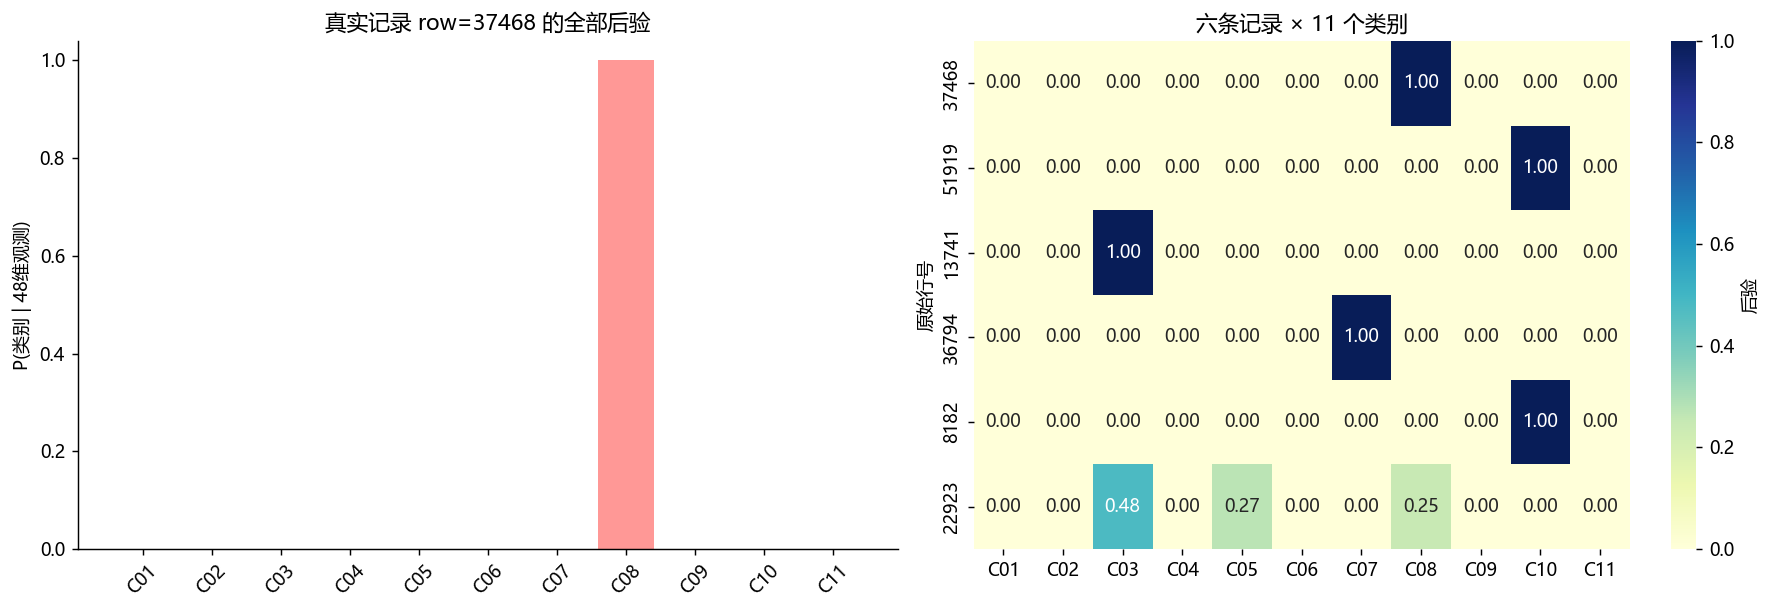

In [7]:
_, six_scores, six_posteriors = manual_gnb_scores(Z_val[:6])
six_table = pd.DataFrame(six_posteriors, columns=class_names, index=X_val.index[:6])
six_table['预测'] = classes[six_posteriors.argmax(axis=1)]
six_table['实际'] = y_val.iloc[:6].to_numpy()
six_table['后验熵'] = -np.sum(six_posteriors * np.log(np.maximum(six_posteriors, 1e-300)), axis=1)
display(six_table.style.format({c: '{:.5g}' for c in class_names + ['后验熵']}))
assert np.allclose(six_posteriors.sum(axis=1), 1)
assert np.array_equal(classes[six_posteriors.argmax(axis=1)], gnb_reference.predict(Z_val[:6]))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].bar(class_names, posterior, color=COLORS)
axes[0].set(title=f'真实记录 row={row_id} 的全部后验', ylabel='P(类别 | 48维观测)', ylim=(0, 1.04))
axes[0].tick_params(axis='x', rotation=45)
sns.heatmap(six_posteriors, ax=axes[1], xticklabels=class_names,
            yticklabels=[str(v) for v in X_val.index[:6]], cmap='YlGnBu', vmin=0, vmax=1,
            annot=True, fmt='.2f', cbar_kws={'label': '后验'})
axes[1].set(title='六条记录 × 11 个类别', ylabel='原始行号')
plt.tight_layout()
show_figure('02_manual_bayes_posteriors')

## 五、模型可视化

### 5.1 高斯密度曲面

二维正态密度为 $f(x)=\{2\pi|\Sigma|^{1/2}\}^{-1}\exp[-\frac12(x-\mu)^\top\Sigma^{-1}(x-\mu)]$。四列分别使用 $(\mu,\Sigma)=((0,0),2I)$、$((2,3),2I)$、$((0,0),\operatorname{diag}(2,6))$、$((0,0),\left[\begin{smallmatrix}2&-1\\-1&2\end{smallmatrix}\right])$。

上排画密度曲面，下排画等密度线。前两列仅改变峰的位置；第三列沿第二个方向拉伸；第四列非零协方差使椭圆旋转。所有曲面用同一坐标范围与色标，便于比较峰值和扩散程度。

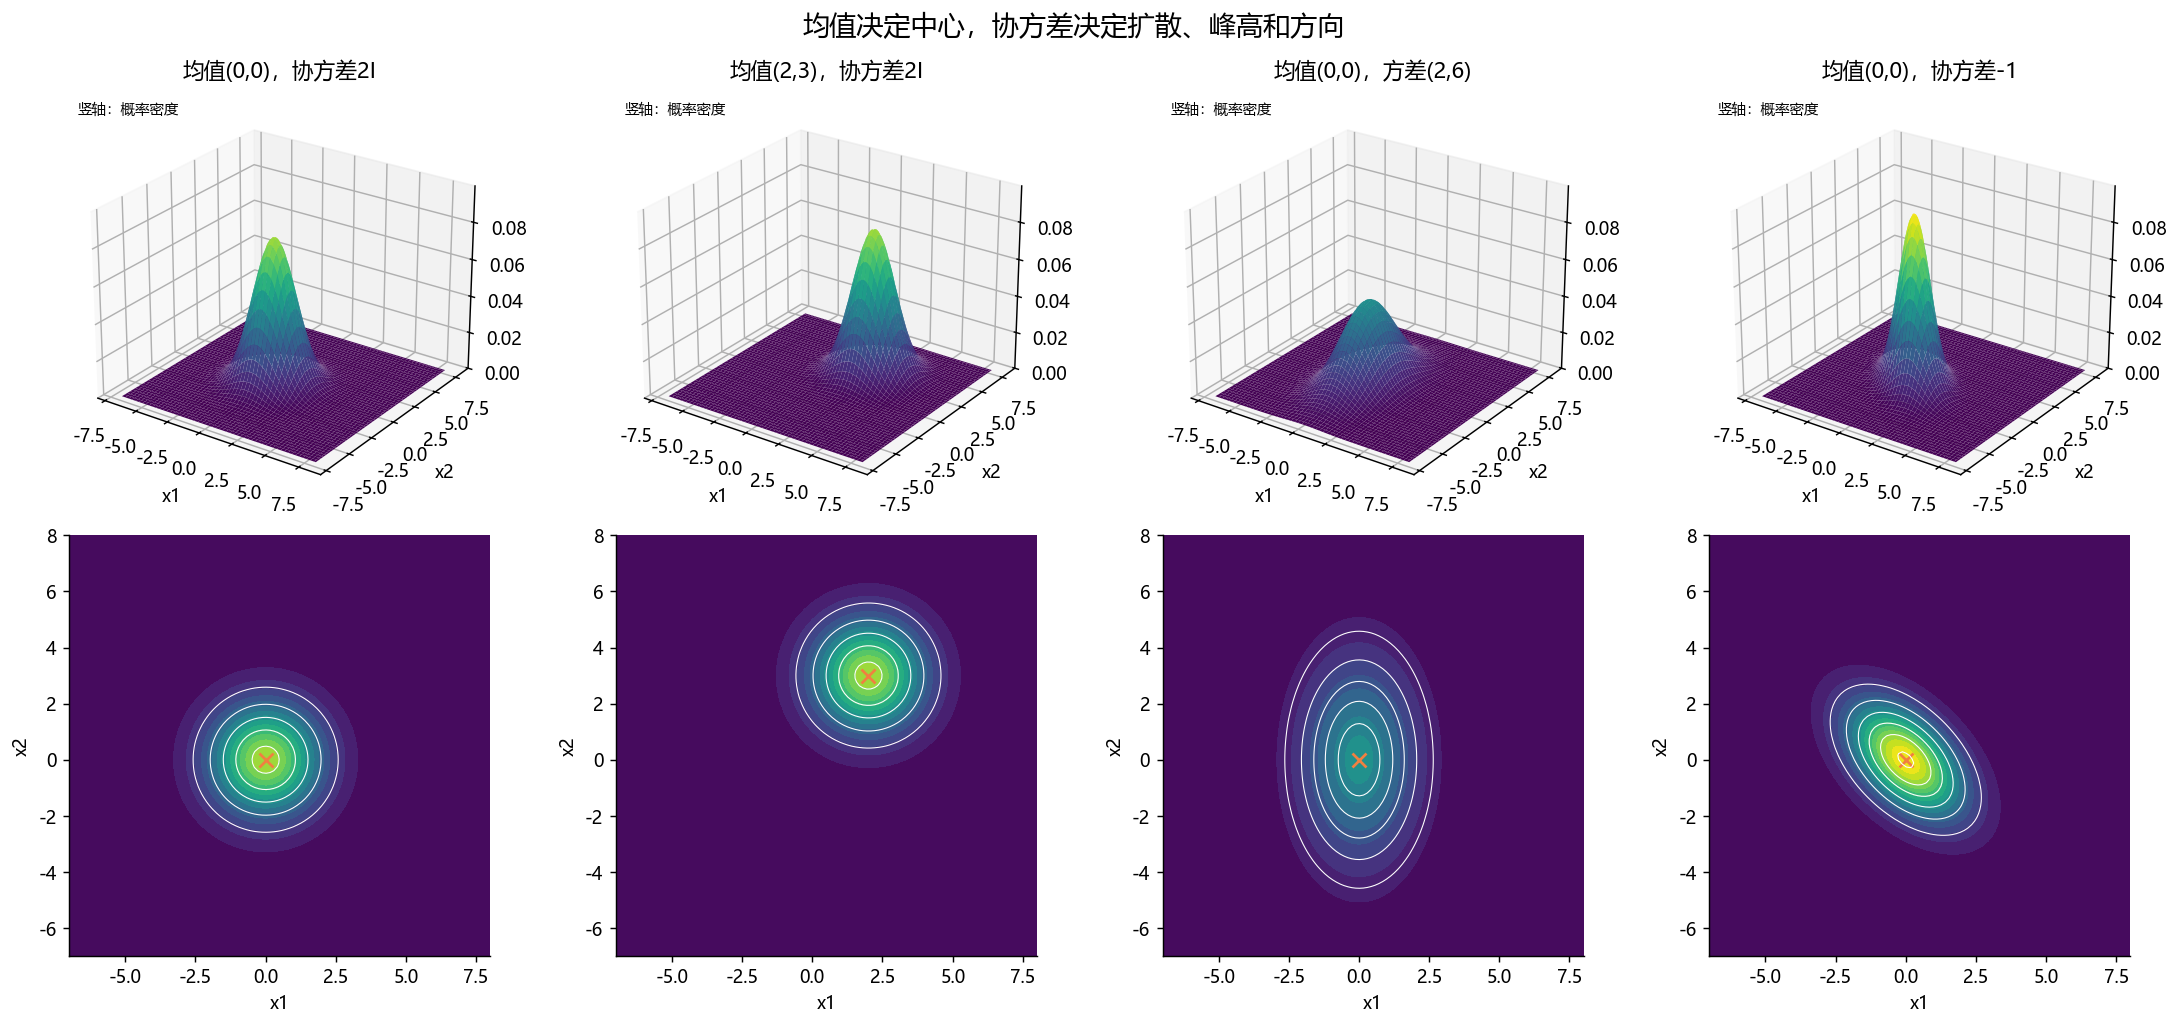

In [8]:
grid_axis = np.linspace(-7, 8, 110)
gx, gy = np.meshgrid(grid_axis, grid_axis)
grid = np.dstack([gx, gy])
settings = [
    ('均值(0,0)，协方差2I', [0,0], [[2,0],[0,2]]),
    ('均值(2,3)，协方差2I', [2,3], [[2,0],[0,2]]),
    ('均值(0,0)，方差(2,6)', [0,0], [[2,0],[0,6]]),
    ('均值(0,0)，协方差-1', [0,0], [[2,-1],[-1,2]]),
]
densities = [multivariate_normal(mean=mu, cov=cov).pdf(grid) for _,mu,cov in settings]
vmax = max(d.max() for d in densities)
fig = plt.figure(figsize=(17, 8))
for i, ((title, mu, cov), density) in enumerate(zip(settings, densities)):
    ax = fig.add_subplot(2, 4, i+1, projection='3d')
    ax.plot_surface(gx, gy, density, cmap='viridis', vmin=0, vmax=vmax,
                    rcount=70, ccount=70, linewidth=0, antialiased=True)
    ax.set(xlabel='x1', ylabel='x2', title=title, zlim=(0,vmax*1.08))
    ax.text2D(.02,.94,'竖轴：概率密度',transform=ax.transAxes,fontsize=8)
    ax.view_init(25, -55)
    ax2 = fig.add_subplot(2,4,i+5)
    ax2.contourf(gx, gy, density, levels=np.linspace(0, vmax, 18), cmap='viridis')
    ax2.contour(gx, gy, density, levels=6, colors='white', linewidths=.6)
    ax2.scatter(*mu, color='#F08040', marker='x', s=60)
    ax2.set(xlabel='x1', ylabel='x2', aspect='equal')
fig.suptitle('均值决定中心，协方差决定扩散、峰高和方向', fontsize=15)
plt.tight_layout()
show_figure('03_lecture_gaussian_surface_and_contours')

### 5.2 协方差与分类边界

用训练数据选取类内平均相关绝对值最大的两个特征作图，选择过程使用训练标签。这一诊断投影专用于展示密度形状，主实验保持全部 48 维特征。每个类分别估计二维均值和 MLE 协方差，并画 90% 概率椭圆。完整协方差模型保留椭圆方向，高斯朴素贝叶斯使用相同边际方差和零协方差。

随后用训练集的单变量类间/类内方差比选择信息较强的两个特征，第二个特征还要求与第一个特征的平均类内相关绝对值小于 0.8。在这个二维投影上比较 GNB、LDA、QDA、KNN 的决策区域。各方法共享同一批验证散点；图中宏F1来自单独训练的二维演示模型，主实验指标来自 48 维完整输入。

训练类内相关诊断选出的特征对： ['F22', 'F23'] 平均绝对相关= 0.9999999852423141


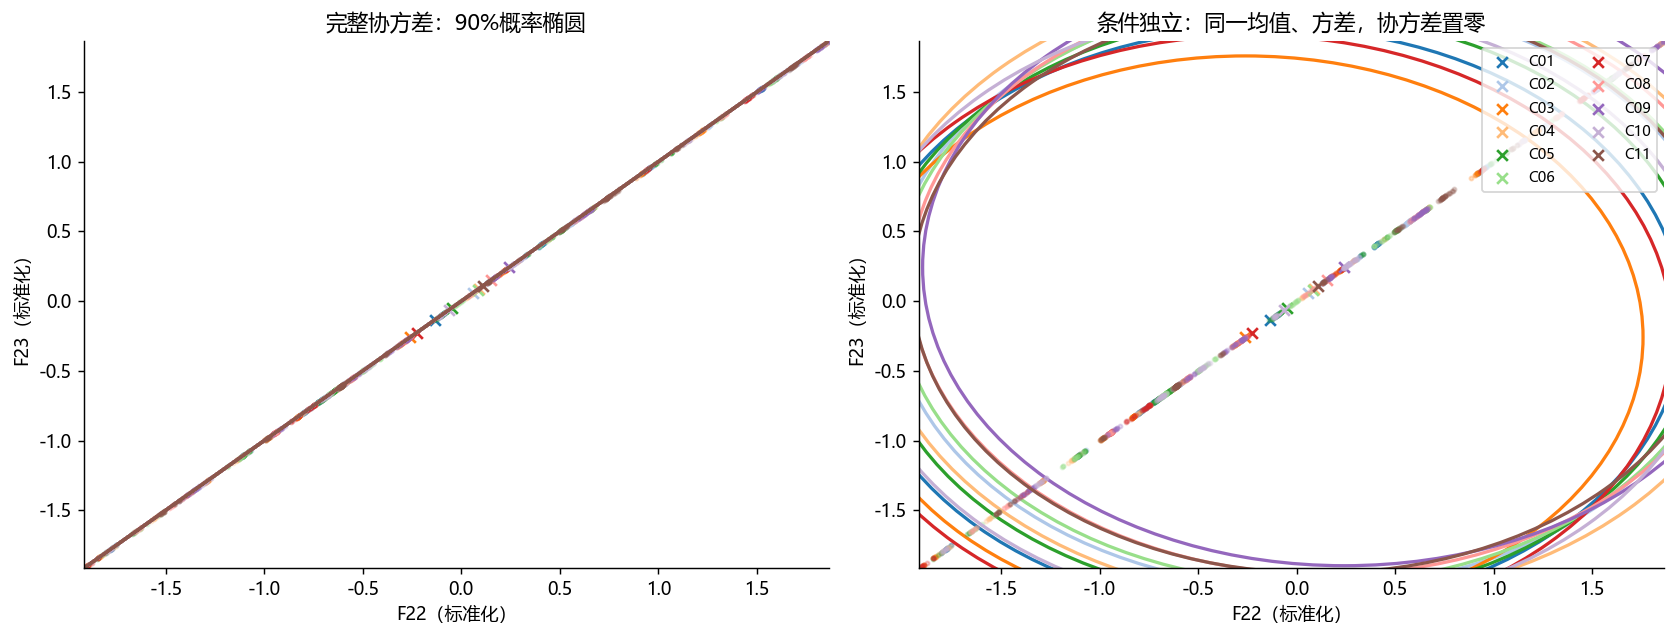

曲面展示类： C02 ；相关系数= 0.9999999790784145 ；协方差条件数= 95595047.52110581


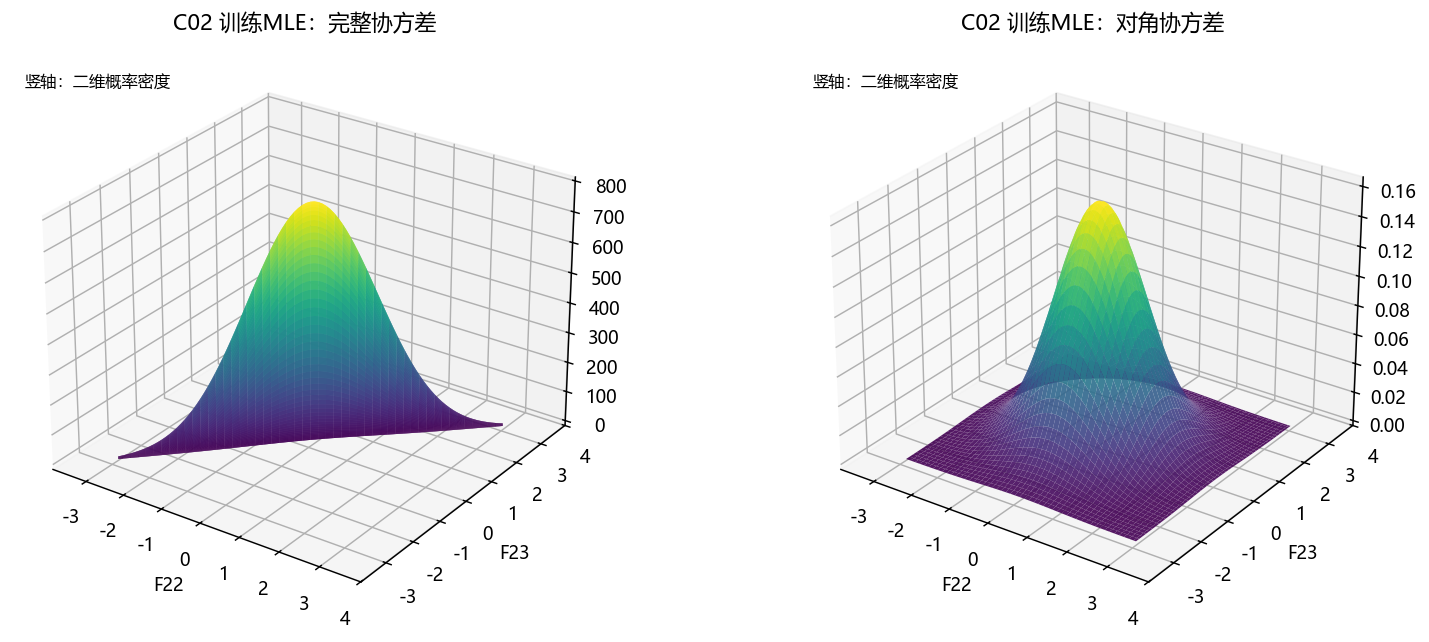

In [9]:
from matplotlib.patches import Ellipse
from scipy.stats import chi2
class_correlations = np.array([np.corrcoef(Z_train[y_train.to_numpy()==k], rowvar=False) for k in classes])
mean_abs_corr = np.mean(np.abs(class_correlations), axis=0)
np.fill_diagonal(mean_abs_corr, -np.inf)
a, b = np.unravel_index(np.argmax(np.triu(mean_abs_corr, 1)), (d,d))
pair = [a,b]
pair_names = [features[a], features[b]]
print('训练类内相关诊断选出的特征对：', pair_names, '平均绝对相关=', mean_abs_corr[a,b])
means2 = means[:, pair]
covs2 = mle_covariances[:, pair, :][:, :, pair]

def draw_cov_ellipse(ax, mu, cov, color, linestyle='-'):
    vals, vecs = np.linalg.eigh(cov)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:,order]
    width, height = 2*np.sqrt(np.maximum(vals,1e-12)*chi2.ppf(.9,2))
    angle = np.degrees(np.arctan2(vecs[1,0],vecs[0,0]))
    ax.add_patch(Ellipse(mu, width, height, angle=angle, fill=False,
                         edgecolor=color, lw=1.8, linestyle=linestyle))

fig, axes = plt.subplots(1,2,figsize=(13,5))
rng = np.random.default_rng(SEED)
for cpos,k in enumerate(classes):
    points = Z_train[y_train.to_numpy()==k][:,pair]
    selected = rng.choice(len(points), min(150,len(points)), replace=False)
    for ax, diagonal in zip(axes,[False, True]):
        ax.scatter(points[selected,0], points[selected,1], s=5, alpha=.25, color=COLORS[cpos])
        cov = np.diag(np.diag(covs2[cpos])) if diagonal else covs2[cpos]
        draw_cov_ellipse(ax, means2[cpos], cov, COLORS[cpos])
        ax.scatter(*means2[cpos], marker='x', s=35, color=COLORS[cpos], label=class_names[cpos])
axes[0].set_title('完整协方差：90%概率椭圆')
axes[1].set_title('条件独立：同一均值、方差，协方差置零')
limits = np.quantile(Z_train[:,pair],[.005,.995],axis=0)
for ax in axes:
    ax.set(xlabel=pair_names[0]+'（标准化）', ylabel=pair_names[1]+'（标准化）',
           xlim=limits[:,0], ylim=limits[:,1])
axes[1].legend(ncol=2, fontsize=8, loc='upper right')
plt.tight_layout()
show_figure('04_real_class_covariance_ellipses')

# 以训练集中协方差行列式最大的类别绘制真实参数密度曲面。
surface_class_index = int(np.argmax(np.linalg.det(covs2)))
mu2, cov2 = means2[surface_class_index], covs2[surface_class_index]
print('曲面展示类：',class_names[surface_class_index],
      '；相关系数=',cov2[0,1]/np.sqrt(cov2[0,0]*cov2[1,1]),
      '；协方差条件数=',np.linalg.cond(cov2))
latent_u,latent_v=np.meshgrid(np.linspace(-3,3,100),np.linspace(-3,3,100))
latent=np.stack([latent_u,latent_v],axis=-1)
fig=plt.figure(figsize=(13,5))
for i,(title,cov) in enumerate([('完整协方差',cov2),('对角协方差',np.diag(np.diag(cov2)))]):
    ax=fig.add_subplot(1,2,i+1,projection='3d')
    # 沿协方差特征向量采样，解析狭窄主轴，避免固定直角网格漏掉密度脊。
    values,vectors=np.linalg.eigh(cov)
    positions=mu2+latent @ (vectors @ np.diag(np.sqrt(values))).T
    uu,vv=positions[:,:,0],positions[:,:,1]
    pdf=multivariate_normal(mean=mu2,cov=cov,allow_singular=False).pdf(positions)
    ax.plot_surface(uu,vv,pdf,cmap='viridis',rcount=90,ccount=90,linewidth=0,alpha=.9)
    ax.set(xlabel=pair_names[0],ylabel=pair_names[1],
           xlim=(mu2[0]-4*np.sqrt(cov2[0,0]),mu2[0]+4*np.sqrt(cov2[0,0])),
           ylim=(mu2[1]-4*np.sqrt(cov2[1,1]),mu2[1]+4*np.sqrt(cov2[1,1])),
           title=f'C{classes[surface_class_index]:02d} 训练MLE：{title}')
    ax.text2D(.02,.92,'竖轴：二维概率密度',transform=ax.transAxes,fontsize=9)
    ax.view_init(27,-55)
plt.tight_layout()
show_figure('05_real_gaussian_density_surfaces')

二维边界诊断特征： ['F12', 'F08'] ；类间/类内方差比= [26.86272453 12.52895708] ；平均类内绝对相关= 0.214770387864239


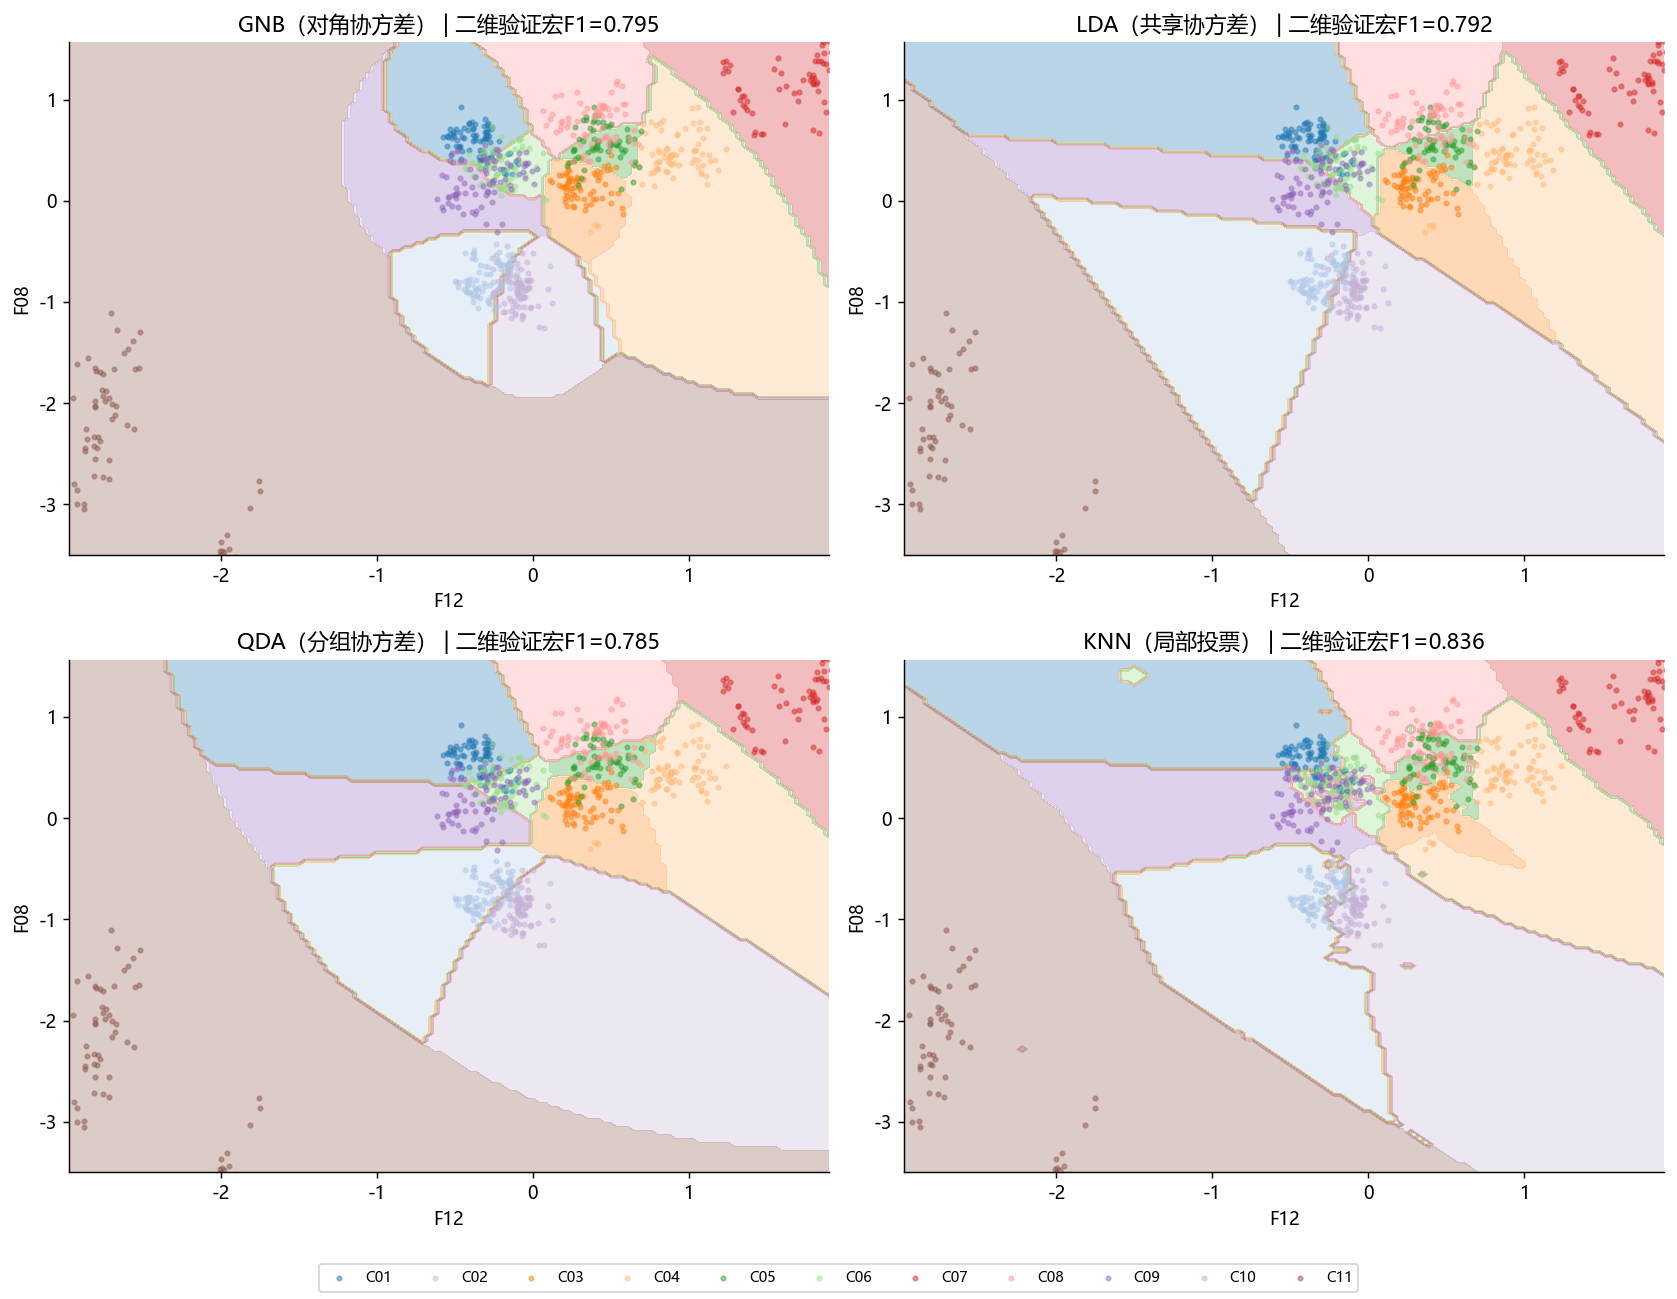

In [10]:
from matplotlib.colors import ListedColormap

between_variance=np.sum(priors[:,None]*(means-Z_train.mean(axis=0))**2,axis=0)
within_variance=np.sum(priors[:,None]*mle_variances,axis=0)
fisher_ratio=between_variance/within_variance
ranked_features=np.argsort(fisher_ratio)[::-1]
demo_a=int(ranked_features[0])
demo_b=int(next(j for j in ranked_features[1:] if mean_abs_corr[demo_a,j]<.8))
demo_pair=[demo_a,demo_b]
demo_limits=np.quantile(Z_train[:,demo_pair],[.005,.995],axis=0)
print('二维边界诊断特征：',[features[j] for j in demo_pair],
      '；类间/类内方差比=',fisher_ratio[demo_pair],
      '；平均类内绝对相关=',mean_abs_corr[demo_a,demo_b])
demo_models = {
    'GNB（对角协方差）': GaussianNB(var_smoothing=1e-3),
    'LDA（共享协方差）': LinearDiscriminantAnalysis(solver='lsqr',shrinkage=.1),
    'QDA（分组协方差）': QuadraticDiscriminantAnalysis(reg_param=.1),
    'KNN（局部投票）': KNeighborsClassifier(n_neighbors=15,weights='distance',algorithm='kd_tree'),
}
xx,yy = np.meshgrid(np.linspace(demo_limits[0,0],demo_limits[1,0],130),
                     np.linspace(demo_limits[0,1],demo_limits[1,1],130))
mesh=np.c_[xx.ravel(),yy.ravel()]
fig,axes=plt.subplots(2,2,figsize=(13,10))
sample = rng.choice(len(Z_val),800,replace=False)
for ax,(name,estimator) in zip(axes.ravel(),demo_models.items()):
    estimator.fit(Z_train[:,demo_pair],y_train)
    mesh_prob = estimator.predict_proba(mesh)
    grid_class = mesh_prob.argmax(axis=1).reshape(xx.shape)
    ax.contourf(xx,yy,grid_class,levels=np.arange(-.5,K+.5,1),cmap=ListedColormap(COLORS),alpha=.3)
    for cpos,k in enumerate(classes):
        chosen=sample[y_val.to_numpy()[sample]==k]
        ax.scatter(Z_val[chosen,demo_a],Z_val[chosen,demo_b],s=6,alpha=.45,
                   color=COLORS[cpos],label=class_names[cpos])
    score=f1_score(y_val,estimator.predict(Z_val[:,demo_pair]),average='macro')
    ax.set(title=f'{name} | 二维验证宏F1={score:.3f}',xlabel=features[demo_a],ylabel=features[demo_b],
           xlim=demo_limits[:,0],ylim=demo_limits[:,1])
fig.legend(*axes[0,0].get_legend_handles_labels(),loc='lower center',ncol=11,fontsize=8)
plt.tight_layout(rect=(0,.035,1,1))
show_figure('06_two_dimensional_decision_boundaries')

### 5.3 正态分布诊断

协方差约束描述相关结构，正态分布假设还规定每个类内边际的形状。用 C01 的训练数据计算标准化四阶中心矩减 3，选择超额峰度最大的特征，并与前节类间/类内方差比最高的特征作对照。这个选择用于呈现训练分布的典型差异与尾部问题。

每个特征按 C01 的均值和标准差变为 $t=(z-\hat\mu)/\hat\sigma$。若拟合正态形状吻合，经验密度接近标准正态曲线，经验分位数接近 Q–Q 图的对角线。直方图只画 $[-5,5]$ 范围，柱高按**全部类内样本数 × 箱宽**归一化；同时报告图外样本比例，保证纵轴仍表示原经验密度。Q–Q 图使用 0.001—0.999 分位数。

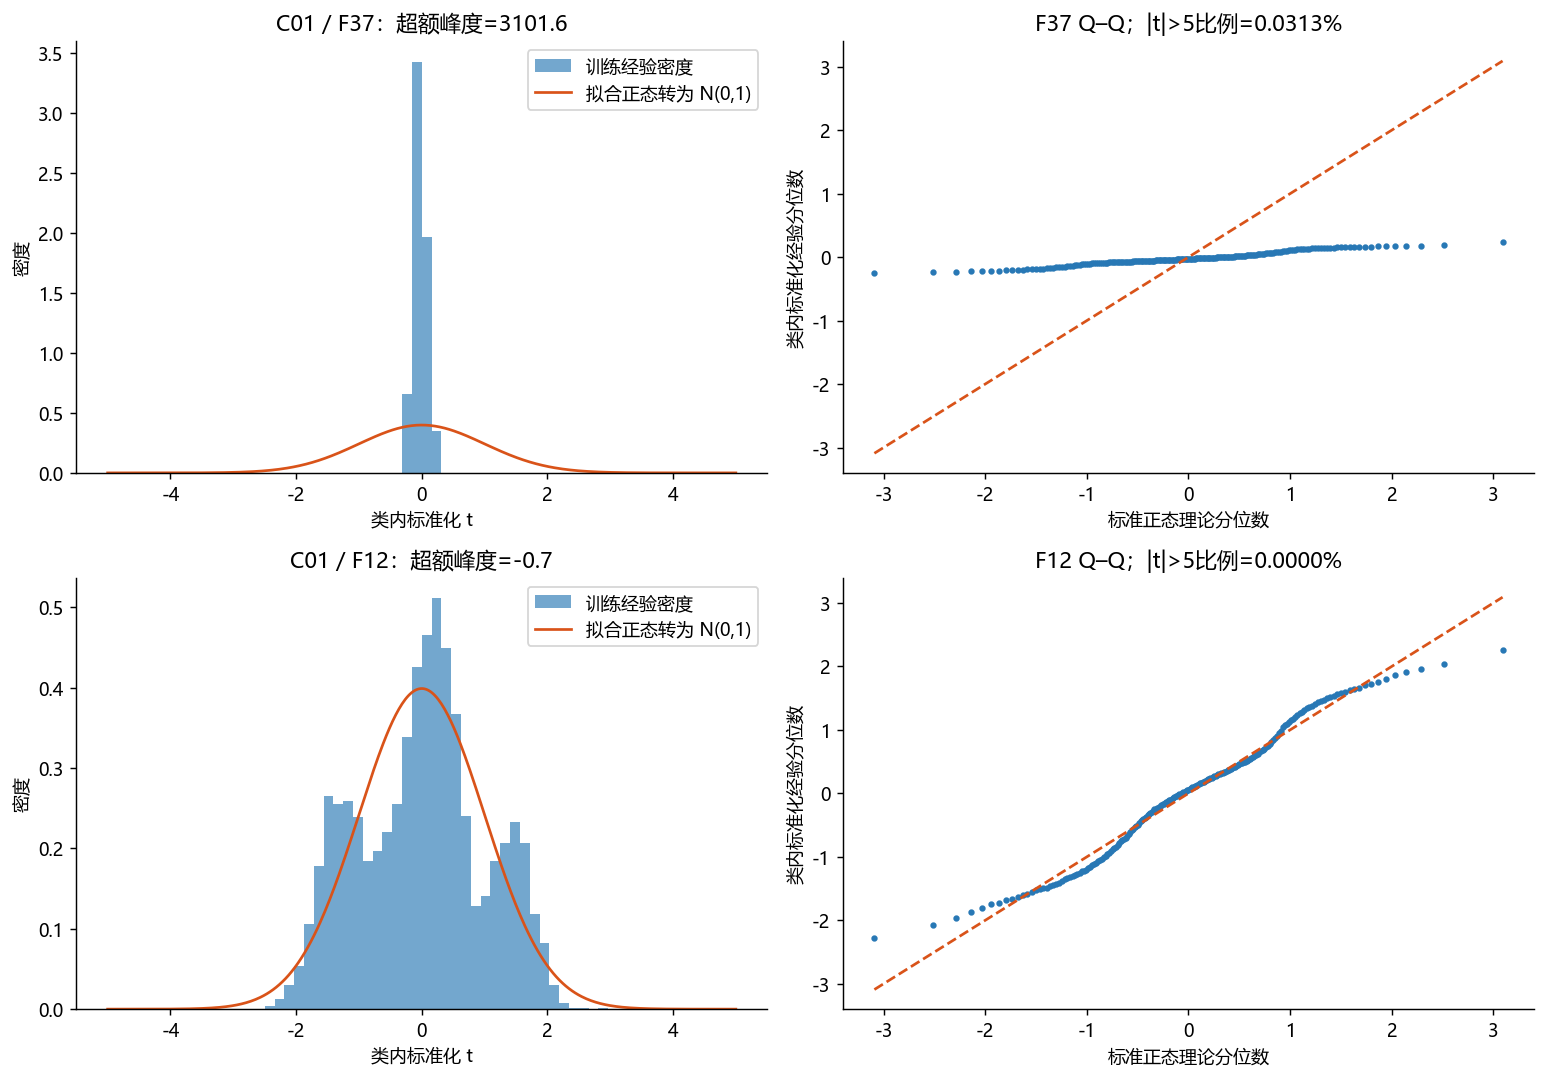

,类别,特征,超额峰度,图外比例_abs_t_gt_5
0,C01,F37,3101.569594,0.000313
1,C01,F12,-0.714888,0.000000


In [11]:
c1_values=Z_train[y_train.to_numpy()==1]
t_c1=(c1_values-means[0])/np.sqrt(mle_variances[0])
excess_kurtosis=np.mean(t_c1**4,axis=0)-3
shape_features=list(dict.fromkeys([int(np.argmax(excess_kurtosis)),demo_a]))
fig,axes=plt.subplots(len(shape_features),2,figsize=(12,4.2*len(shape_features)),squeeze=False)
shape_rows=[]
for row,j in enumerate(shape_features):
    values=t_c1[:,j]
    bins=np.linspace(-5,5,65)
    width=bins[1]-bins[0]
    axes[row,0].hist(values,bins=bins,weights=np.full(len(values),1/(len(values)*width)),
                     alpha=.65,label='训练经验密度',color='#2878B5')
    axis=np.linspace(-5,5,400)
    axes[row,0].plot(axis,norm.pdf(axis),color='#D95319',label='拟合正态转为 N(0,1)')
    outside=np.mean(np.abs(values)>5)
    axes[row,0].set(title=f'C01 / {features[j]}：超额峰度={excess_kurtosis[j]:.1f}',
                    xlabel='类内标准化 t',ylabel='密度')
    quantiles=np.linspace(.001,.999,199)
    theoretical=norm.ppf(quantiles)
    empirical=np.quantile(values,quantiles)
    axes[row,1].plot(theoretical,empirical,'o',ms=2.5,color='#2878B5')
    lo=min(theoretical.min(),empirical.min());hi=max(theoretical.max(),empirical.max())
    axes[row,1].plot([lo,hi],[lo,hi],'--',color='#D95319')
    axes[row,1].set(title=f'{features[j]} Q–Q；|t|>5比例={outside:.4%}',
                    xlabel='标准正态理论分位数',ylabel='类内标准化经验分位数')
    axes[row,0].legend()
    shape_rows.append({'类别':'C01','特征':features[j],'超额峰度':excess_kurtosis[j],
                       '图外比例_abs_t_gt_5':outside})
plt.tight_layout()
show_figure('13_gaussian_shape_diagnostics')
display(pd.DataFrame(shape_rows))

## 六、离散朴素贝叶斯

### 6.1 概率估计与平滑

连续特征在训练折内用分位数切成 $B_j$ 个箱，箱编号为 $b_j\in\{0,\ldots,B_j-1\}$。设
$N_{kjb}=\sum_{i:y_i=k}\mathbf1(b_{ij}=b)$，$\theta_{kjb}=P(b_j=b\mid Y=k)$。
对固定类和特征，$\ell_{kj}=\sum_bN_{kjb}\log\theta_{kjb}$，约束 $\sum_b\theta_{kjb}=1$。
拉格朗日求导给出 MLE：$\hat\theta_{kjb}=N_{kjb}/n_k$。

训练中未出现的箱会获得零 MLE；在连乘中，其对应类的似然变成零。用对称 Dirichlet$(\alpha,\ldots,\alpha)$ 先验，后验为 Dirichlet$(N_{kj0}+\alpha,\ldots,N_{kj,B_j-1}+\alpha)$，其**后验均值 / 单次预测概率**为

$$\tilde\theta_{kjb}=\frac{N_{kjb}+\alpha}{n_k+\alpha B_j},\qquad\alpha>0.$$

写 $\beta_c=N_{kjc}+\alpha$，Dirichlet 密度的归一化常数为 $\mathcal B(\beta)=\prod_c\Gamma(\beta_c)/\Gamma(\sum_c\beta_c)$。对参数积分的预测概率为

$$P(b_{new}=b\mid\mathcal D,Y=k)=\int\theta_b\,p(\theta\mid\mathcal D)\,d\theta
=\frac{\mathcal B(\beta+e_b)}{\mathcal B(\beta)}
=\frac{\Gamma(\beta_b+1)}{\Gamma(\beta_b)}\frac{\Gamma(\sum_c\beta_c)}{\Gamma(\sum_c\beta_c+1)}
=\frac{\beta_b}{\sum_c\beta_c}.$$

$\alpha=1$ 是加一（拉普拉斯）平滑；$\alpha\downarrow0$ 趋近 MLE，较大 $\alpha$ 将箱概率拉向 $1/B_j$。这里使用后验预测均值；Dirichlet 后验众数在内点条件下对应 $(N+\alpha-1)/(n+B(\alpha-1))$，二者的估计目标不同。

离散后验为

$$P(Y=k\mid b)=\frac{\hat\pi_k\prod_j\tilde\theta_{kj,b_j}}{\sum_r\hat\pi_r\prod_j\tilde\theta_{rj,b_j}}.$$

分箱阈值和类别计数全部由训练数据估计。最终调参会同时选择箱数和平滑强度。

In [12]:
# 先用一个两类、三箱的透明计数例子展示零频率与平滑的计算。
toy_counts = np.array([[8,2,0],[1,3,6]])
toy_n = toy_counts.sum(axis=1)
toy_prior = toy_n / toy_n.sum()
toy_unsmoothed = toy_counts / toy_n[:,None]
toy_smoothed = (toy_counts+1)/(toy_n[:,None]+3)
toy_query_bin = 2
toy_joint_raw = toy_prior * toy_unsmoothed[:,toy_query_bin]
toy_joint_smooth = toy_prior * toy_smoothed[:,toy_query_bin]
display(pd.DataFrame({
    '类别':['A','B'], '箱2计数':toy_counts[:,2], '类计数':toy_n,
    'MLE箱2概率':toy_unsmoothed[:,2], '加一箱2概率':toy_smoothed[:,2],
    '未平滑后验':toy_joint_raw/toy_joint_raw.sum(),
    '加一后验':toy_joint_smooth/toy_joint_smooth.sum(),
}))
display(Math(r'\theta_{A,2}=\frac{0+1}{10+3}=\frac1{13},\quad '
             r'\theta_{B,2}=\frac{6+1}{10+3}=\frac7{13},\quad '
             r'P(A\mid b=2)=\frac{(1/2)(1/13)}{(1/2)(1/13)+(1/2)(7/13)}=\frac18.'))

# 再对 48 维真实记录复算 CategoricalNB 的全部类别后验。
discretizer = KBinsDiscretizer(n_bins=5, encode='ordinal', strategy='quantile',
                             subsample=None, quantile_method='averaged_inverted_cdf')
B_train=discretizer.fit_transform(X_train).astype(int)
B_example=discretizer.transform(X_val.iloc[[example_position]]).astype(int)[0]
alpha=1.0
categorical_model=CategoricalNB(alpha=alpha).fit(B_train,y_train)
cat_log_likelihood=np.zeros(K)
cat_parameter_rows=[]
for cpos,k in enumerate(classes):
    mask=y_train.to_numpy()==k
    for j in range(d):
        B_j=int(discretizer.n_bins_[j])
        count=int(np.sum(B_train[mask,j]==B_example[j]))
        theta=(count+alpha)/(counts[cpos]+alpha*B_j)
        cat_log_likelihood[cpos]+=np.log(theta)
        cat_parameter_rows.append([k,features[j],B_example[j],count,counts[cpos],B_j,theta])
cat_parameters=pd.DataFrame(cat_parameter_rows,columns=[
    '类别','特征','查询箱','该箱类内计数','类计数','箱数','平滑条件概率'])
display(cat_parameters.head(16))
display(Markdown('**F01 在全部类别中的真实箱计数与平滑条件概率：**'))
display(cat_parameters[cat_parameters['特征']=='F01'])
first_cat=cat_parameters.iloc[0]
display(Math(rf'\widetilde\theta_{{1,1,{B_example[0]}}}'
             rf'=\frac{{{int(first_cat["该箱类内计数"])}+{alpha:g}}}'
             rf'{{{counts[0]}+{alpha:g}\times{int(first_cat["箱数"])}}}'
             rf'={first_cat["平滑条件概率"]:.9f}'))
cat_scores=np.log(priors)+cat_log_likelihood
cat_posterior=np.exp(cat_scores-logsumexp(cat_scores))
np.testing.assert_allclose(cat_posterior,
                           categorical_model.predict_proba(B_example[None,:])[0],atol=1e-10)
display(pd.DataFrame({'类别':class_names,'log类条件概率':cat_log_likelihood,
                      'log联合概率':cat_scores,'后验':cat_posterior}))
print('真实数据全部 11 类后验复算通过；当前离散预测为',classes[np.argmax(cat_posterior)])
show_table_details(cat_parameters, '展开全部 528 项离散箱计数与条件概率')

,类别,箱2计数,类计数,MLE箱2概率,加一箱2概率,未平滑后验,加一后验
0,A,0,10,0.0,0.076923,0.0,0.125
1,B,6,10,0.6,0.538462,1.0,0.875


<IPython.core.display.Math object>

,类别,特征,查询箱,该箱类内计数,类计数,箱数,平滑条件概率
0,1,F01,2,864,3191,5,0.270651
1,1,F02,2,616,3191,5,0.193054
2,1,F03,1,572,3191,5,0.179287
3,1,F04,3,414,3191,5,0.129850
4,1,F05,1,453,3191,5,0.142053
5,1,F06,3,671,3191,5,0.210263
6,1,F07,4,778,3191,5,0.243742
7,1,F08,4,776,3191,5,0.243116
8,1,F09,4,778,3191,5,0.243742
9,1,F10,3,0,3191,5,0.000313


**F01 在全部类别中的真实箱计数与平滑条件概率：**

,类别,特征,查询箱,该箱类内计数,类计数,箱数,平滑条件概率
0,1,F01,2,864,3191,5,0.270651
48,2,F01,2,639,3191,5,0.200250
96,3,F01,2,796,3192,5,0.249296
144,4,F01,2,480,3191,5,0.150501
192,5,F01,2,669,3191,5,0.209637
240,6,F01,2,788,3191,5,0.246871
288,7,F01,2,574,3191,5,0.179912
336,8,F01,2,618,3192,5,0.193619
384,9,F01,2,593,3191,5,0.185857
432,10,F01,2,679,3192,5,0.212699


<IPython.core.display.Math object>

,类别,log类条件概率,log联合概率,后验
0,C01,-98.683586,-101.081595,2.506766e-13
1,C02,-120.533100,-122.931109,8.128124e-23
2,C03,-87.177264,-89.574960,2.491048e-08
3,C04,-81.464552,-83.862561,7.537810e-06
4,C05,-73.180316,-75.578325,2.985681e-02
5,C06,-107.164187,-109.562196,5.200387e-17
6,C07,-91.959176,-94.357185,2.086835e-10
7,C08,-69.699606,-72.097302,9.701356e-01
8,C09,-107.135497,-109.533506,5.351746e-17
9,C10,-118.847847,-121.245543,4.385536e-22


真实数据全部 11 类后验复算通过；当前离散预测为 8


类别,特征,查询箱,该箱类内计数,类计数,箱数,平滑条件概率
1,F01,2,864,3191,5,0.2706508
1,F02,2,616,3191,5,0.1930538
1,F03,1,572,3191,5,0.1792866
1,F04,3,414,3191,5,0.1298498
1,F05,1,453,3191,5,0.1420526
1,F06,3,671,3191,5,0.2102628
1,F07,4,778,3191,5,0.2437422
1,F08,4,776,3191,5,0.2431164
1,F09,4,778,3191,5,0.2437422
1,F10,3,0,3191,5,0.0003128911


## 七、KNN 分类

### 7.1 距离与投票

课件第 51—57 页讨论向量范数，第 90 页把“相近样本倾向同类”列为最近邻的归纳偏置。标准化后定义

$$d_p(z,z_i)=\left(\sum_{j=1}^{d}|z_j-z_{ij}|^p\right)^{1/p}.$$

$p=1$ 是 Manhattan 距离，$p=2$ 是 Euclidean 距离。取最近的 $q$ 个训练样本 $\mathcal N_q(z)$，均匀投票得到

$$\hat P(Y=k\mid z)=\frac1q\sum_{i\in\mathcal N_q(z)}\mathbf1(y_i=k).$$

距离投票使用 $w_i=1/d_p(z,z_i)$，并按 $\sum_i w_i$ 归一化；若邻居距离为零，sklearn 只对距离为零的邻居计权。$q$ 小时边界灵活、局部波动较大，$q$ 增大后决策更平滑。与高斯生成模型相比，KNN 把计算重点放在查询样本附近的经验类别组成。

### 7.2 邻居投票计算

In [13]:
knn_demo=KNeighborsClassifier(n_neighbors=7,weights='distance',p=2,algorithm='brute',n_jobs=1)
knn_demo.fit(Z_train,y_train)
distances, neighbor_positions=knn_demo.kneighbors(z_example[None,:])
distances,neighbor_positions=distances[0],neighbor_positions[0]
neighbor_labels=y_train.to_numpy()[neighbor_positions]
weights=(distances==0).astype(float) if np.any(distances==0) else 1/distances
knn_manual=np.array([weights[neighbor_labels==k].sum() for k in classes])/weights.sum()
display(pd.DataFrame({'邻居顺位':np.arange(1,8),'训练原始行号':X_train.index[neighbor_positions],
                      '距离':distances,'类别':neighbor_labels,'归一化权重':weights/weights.sum()}))
display(pd.DataFrame({'类别':class_names,'KNN后验估计':knn_manual}))
np.testing.assert_allclose(knn_manual,knn_demo.predict_proba(z_example[None,:])[0],atol=1e-12)
print('手工 KNN 距离投票与 sklearn 一致。')

,邻居顺位,训练原始行号,距离,类别,归一化权重
0,1,37570,1.033237,8,0.170178
1,2,37603,1.182077,8,0.148750
2,3,37568,1.231760,8,0.142750
3,4,37438,1.233142,8,0.142590
4,5,37465,1.279959,8,0.137375
5,6,37366,1.330426,8,0.132163
6,7,37625,1.393356,8,0.126194


,类别,KNN后验估计
0,C01,0.0
1,C02,0.0
2,C03,0.0
3,C04,0.0
4,C05,0.0
5,C06,0.0
6,C07,0.0
7,C08,1.0
8,C09,0.0
9,C10,0.0


手工 KNN 距离投票与 sklearn 一致。


## 八、模型调参

### 8.1 指标与参数范围

主指标采用宏平均 F1：对各类 $F1_k=2P_kR_k/(P_k+R_k)$ 求平均，使 11 类在评价中权重相同。辅助报告 Accuracy、宏召回率、Log Loss 和多类 Brier 分数。Log Loss 是课件交叉熵的样本形式：$-m^{-1}\sum_i\log\gamma_{y_i}(x_i)$；多类 Brier 定义为 $m^{-1}\sum_i\sum_k(\gamma_k(x_i)-\mathbf1(y_i=k))^2$，这里对类别求和后再对样本平均。

|模型|调节参数|优化含义|
|---|---|---|
|标准化 GNB|`var_smoothing`: $10^{-10}$ 到 $10^{-1}$，10 个对数值|控制类内小方差导致的尖峰|
|LDA|`shrinkage`: 0、0.01、0.1、0.5、auto|收缩共享协方差，改善求逆稳定性|
|QDA|`reg_param`: 0、$10^{-8}$、$10^{-6}$、$10^{-4}$、0.001、0.01、0.1、0.5、0.9|细查接近零的小幅收缩，并比较较强收缩|
|CategoricalNB|`n_bins`: 3/5/8；`alpha`: 0.1/1/10|平衡离散分辨率、稀疏计数和平滑|
|KNN|`n_neighbors`: 3/7/15/31；`weights`: uniform/distance；`p`: 1/2|比较邻域规模、投票权重和距离范数|

QDA 在标准化空间近似使用 $(1-r)S_k+rI$，$S_k$ 基于无偏类协方差。固定数值 LDA 收缩使用 $(1-r)S+r\operatorname{tr}(S)I/d$，`auto` 使用 Ledoit–Wolf 型估计。两种收缩参数与 GNB 的加性方差平滑各有定义，表格分别记录其值。

保留未标准化 GaussianNB 与默认 KNN 作为优化前对照。优化前后的变化可以分解为量纲处理、参数调整和协方差结构变化。

QDA 的数值秩提示按模型与训练阶段捕获，汇总出现次数并在文末列出原始信息。类内最小特征值、条件数和正则化强度一起解释数值稳定性；所有训练结果仍正常参与预先设定的评分规则。

In [14]:
def scaled_model(model):
    return Pipeline([('scale',StandardScaler()),('model',model)])

model_specs={
    'GaussianNB':(scaled_model(GaussianNB()),{'model__var_smoothing':np.logspace(-10,-1,10)}),
    'LDA':(scaled_model(LinearDiscriminantAnalysis(solver='lsqr')),
           {'model__shrinkage':[0,.01,.1,.5,'auto']}),
    'QDA':(scaled_model(QuadraticDiscriminantAnalysis()),
           {'model__reg_param':[0,1e-8,1e-6,1e-4,.001,.01,.1,.5,.9]}),
    'CategoricalNB':(Pipeline([
        ('bins',KBinsDiscretizer(encode='ordinal',strategy='quantile',subsample=None,
                                quantile_method='averaged_inverted_cdf')),
        ('model',CategoricalNB())]),
        {'bins__n_bins':[3,5,8],'model__alpha':[.1,1,10]}),
    'KNN':(scaled_model(KNeighborsClassifier(algorithm='brute',n_jobs=1)),
           {'model__n_neighbors':[3,7,15,31],'model__weights':['uniform','distance'],
            'model__p':[1,2]}),
}
cv=StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED)
screen_searches={}
searches={}
cv_records=[]
warning_records=[]

def fit_with_diagnostics(estimator, x, target, model_name, phase):
    # 保留每种提示的原文与次数，用短表替代重复堆叠的运行提示。
    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter('always')
        estimator.fit(x,target)
    messages={}
    for item in captured:
        key=(item.category.__name__,str(item.message))
        messages[key]=messages.get(key,0)+1
    for (category,message),count in messages.items():
        warning_records.append({'model':model_name,'phase':phase,'category':category,
                                'message':message,'count':count})
    if captured:
        print(f'{model_name} / {phase}：捕获{len(captured)}条数值提示，原文与次数见文末数值诊断表。')
    return estimator

def cv_refit_rule(results):
    # 完全同分时选择交叉熵较小的参数；neg_log_loss 越大越好。
    order=np.lexsort((-np.asarray(results['mean_test_log_loss']),
                      -np.asarray(results['mean_test_f1_macro'])))
    return int(order[0])

for name,(pipe,param_grid) in model_specs.items():
    start=time.perf_counter()
    search=GridSearchCV(pipe,param_grid,cv=cv,
                        scoring={'f1_macro':'f1_macro','log_loss':'neg_log_loss'},
                        refit=cv_refit_rule,n_jobs=1,return_train_score=True,error_score='raise')
    fit_with_diagnostics(search,X_tune,y_tune,name,'12000条初筛')
    screen_searches[name]=search
    table=pd.DataFrame(search.cv_results_)
    table['model']=name
    table['stage']='初筛12000条'
    cv_records.append(table)
    print(f'{name}: {len(table)}组参数×3折，最优宏F1={table.loc[search.best_index_,"mean_test_f1_macro"]:.5f}，'
          f'耗时={time.perf_counter()-start:.1f}s，参数={search.best_params_}')
for name,screen in screen_searches.items():
    start=time.perf_counter()
    ranking=pd.DataFrame(screen.cv_results_).sort_values(
        ['mean_test_f1_macro','mean_test_log_loss'],ascending=[False,False]).head(3)
    short_grid=[{key:[value] for key,value in params.items()} for params in ranking['params']]
    refined=GridSearchCV(clone(model_specs[name][0]),short_grid,cv=cv,
                         scoring={'f1_macro':'f1_macro','log_loss':'neg_log_loss'},
                         refit=cv_refit_rule,n_jobs=1,return_train_score=True,error_score='raise')
    fit_with_diagnostics(refined,X_train,y_train,name,'完整训练集精筛')
    searches[name]=refined
    table=pd.DataFrame(refined.cv_results_)
    table['model']=name
    table['stage']='完整训练集精筛'
    cv_records.append(table)
    print(f'{name} 完整训练集精筛：宏F1={table.loc[refined.best_index_,"mean_test_f1_macro"]:.5f}，'
          f'耗时={time.perf_counter()-start:.1f}s，最终参数={refined.best_params_}')
cv_all=pd.concat(cv_records,ignore_index=True)
display(cv_all[['model','stage','params','mean_train_f1_macro','mean_test_f1_macro',
                'std_test_f1_macro','mean_test_log_loss','mean_fit_time']]
        .sort_values(['model','stage','mean_test_f1_macro'],ascending=[True,True,False]).groupby(['model','stage']).head(3))
eigenvalues=np.linalg.eigvalsh(mle_covariances)
display(pd.DataFrame({'类别':class_names,'最小特征值':eigenvalues[:,0],
                      '最大特征值':eigenvalues[:,-1],
                      '谱条件数':eigenvalues[:,-1]/eigenvalues[:,0],
                      '低于1e-4的特征值数':(eigenvalues<1e-4).sum(axis=1)}))
show_table_details(cv_all[['model','stage','params','mean_train_f1_macro','mean_test_f1_macro','std_test_f1_macro','mean_test_log_loss']], '展开全部 64 组交叉验证候选记录（log_loss 列为负交叉熵，越大越好）')

GaussianNB: 10组参数×3折，最优宏F1=0.80726，耗时=7.3s，参数={'model__var_smoothing': np.float64(0.001)}


LDA: 5组参数×3折，最优宏F1=0.85467，耗时=1.2s，参数={'model__shrinkage': 0}


QDA / 12000条初筛：捕获110条数值提示，原文与次数见文末数值诊断表。
QDA: 9组参数×3折，最优宏F1=0.90274，耗时=8.9s，参数={'model__reg_param': 1e-06}


CategoricalNB: 9组参数×3折，最优宏F1=0.83720，耗时=4.5s，参数={'bins__n_bins': 8, 'model__alpha': 0.1}


KNN: 16组参数×3折，最优宏F1=0.94251，耗时=124.0s，参数={'model__n_neighbors': 7, 'model__p': 1, 'model__weights': 'distance'}


GaussianNB 完整训练集精筛：宏F1=0.70531，耗时=4.9s，最终参数={'model__var_smoothing': np.float64(0.001)}


... (3 outputs left out)

KNN 完整训练集精筛：宏F1=0.97188，耗时=269.1s，最终参数={'model__n_neighbors': 15, 'model__p': 1, 'model__weights': 'distance'}


,model,stage,params,mean_train_f1_macro,mean_test_f1_macro,std_test_f1_macro,mean_test_log_loss,mean_fit_time
30,CategoricalNB,初筛12000条,"{'bins__n_bins': 8, 'model__alpha': 0.1}",0.852647,0.837197,0.006675,-0.776259,0.068281
31,CategoricalNB,初筛12000条,"{'bins__n_bins': 8, 'model__alpha': 1}",0.851547,0.836471,0.006880,-0.766847,0.069374
32,CategoricalNB,初筛12000条,"{'bins__n_bins': 8, 'model__alpha': 10}",0.839983,0.825562,0.009524,-0.733766,0.082452
58,CategoricalNB,完整训练集精筛,"{'bins__n_bins': 8, 'model__alpha': 0.1}",0.858209,0.853927,0.004579,-0.730514,0.158677
59,CategoricalNB,完整训练集精筛,"{'bins__n_bins': 8, 'model__alpha': 1}",0.858037,0.853592,0.004653,-0.726893,0.135070
60,CategoricalNB,完整训练集精筛,"{'bins__n_bins': 8, 'model__alpha': 10}",0.854581,0.849910,0.005018,-0.708017,0.130141
7,GaussianNB,初筛12000条,{'model__var_smoothing': 0.001},0.817847,0.807262,0.025869,-1.004460,0.027263
6,GaussianNB,初筛12000条,{'model__var_smoothing': 0.0001},0.817993,0.806104,0.025186,-1.028433,0.040674
4,GaussianNB,初筛12000条,{'model__var_smoothing': 1e-06},0.815199,0.804188,0.024611,-1.051563,0.026234
49,GaussianNB,完整训练集精筛,{'model__var_smoothing': 0.001},0.707349,0.705307,0.061833,-2.240353,0.061190


,类别,最小特征值,最大特征值,谱条件数,低于1e-4的特征值数
0,C01,1.840102e-11,10.349915,5.624642e+11,12
1,C02,1.813990e-11,23.053205,1.270856e+12,12
2,C03,8.700281e-12,7.837993,9.008897e+11,13
3,C04,1.817736e-11,10.520666,5.787784e+11,13
4,C05,1.476307e-11,8.744539,5.923252e+11,12
5,C06,1.733699e-11,24.312240,1.402334e+12,13
6,C07,6.182667e-11,24.295497,3.929615e+11,12
7,C08,1.145028e-11,8.938163,7.806066e+11,13
8,C09,1.843417e-11,9.317313,5.054372e+11,12
9,C10,1.666891e-11,8.831887,5.298419e+11,13


model,stage,params,mean_train_f1_macro,mean_test_f1_macro,std_test_f1_macro,mean_test_log_loss
GaussianNB,初筛12000条,{'model__var_smoothing': 1e-10},0.8152449,0.8040291,0.02452838,-1.052292
GaussianNB,初筛12000条,{'model__var_smoothing': 1e-09},0.8152449,0.8040291,0.02452838,-1.052291
GaussianNB,初筛12000条,{'model__var_smoothing': 1e-08},0.8152449,0.8040291,0.02452838,-1.052285
GaussianNB,初筛12000条,{'model__var_smoothing': 1e-07},0.8152449,0.8040291,0.02452838,-1.052217
GaussianNB,初筛12000条,{'model__var_smoothing': 1e-06},0.815199,0.8041876,0.02461113,-1.051563
GaussianNB,初筛12000条,{'model__var_smoothing': 1e-05},0.8157862,0.8035011,0.02407545,-1.046445
GaussianNB,初筛12000条,{'model__var_smoothing': 0.0001},0.8179926,0.8061035,0.02518639,-1.028433
GaussianNB,初筛12000条,{'model__var_smoothing': 0.001},0.8178471,0.8072619,0.02586931,-1.00446
GaussianNB,初筛12000条,{'model__var_smoothing': 0.01},0.8036153,0.7902186,0.02519419,-0.9693971
GaussianNB,初筛12000条,{'model__var_smoothing': 0.1},0.6821354,0.6722959,0.01359778,-1.156028


### 8.2 调参结果

GNB 与 QDA 的曲线展示正则化增强对训练折和验证折分数的影响；KNN 图固定欧氏距离，分别画两种投票方式下的邻居数。CategoricalNB 热图对比箱数与平滑强度。误差棒表示三折分数的标准差，描述该调参子样本中的分折波动。

`weights='distance'` 的 KNN 在其训练样本上包含零距离自身，训练 F1 常接近 1；验证折表现承担参数选择作用。其训练—验证差距同时包含这一插值结构的影响。

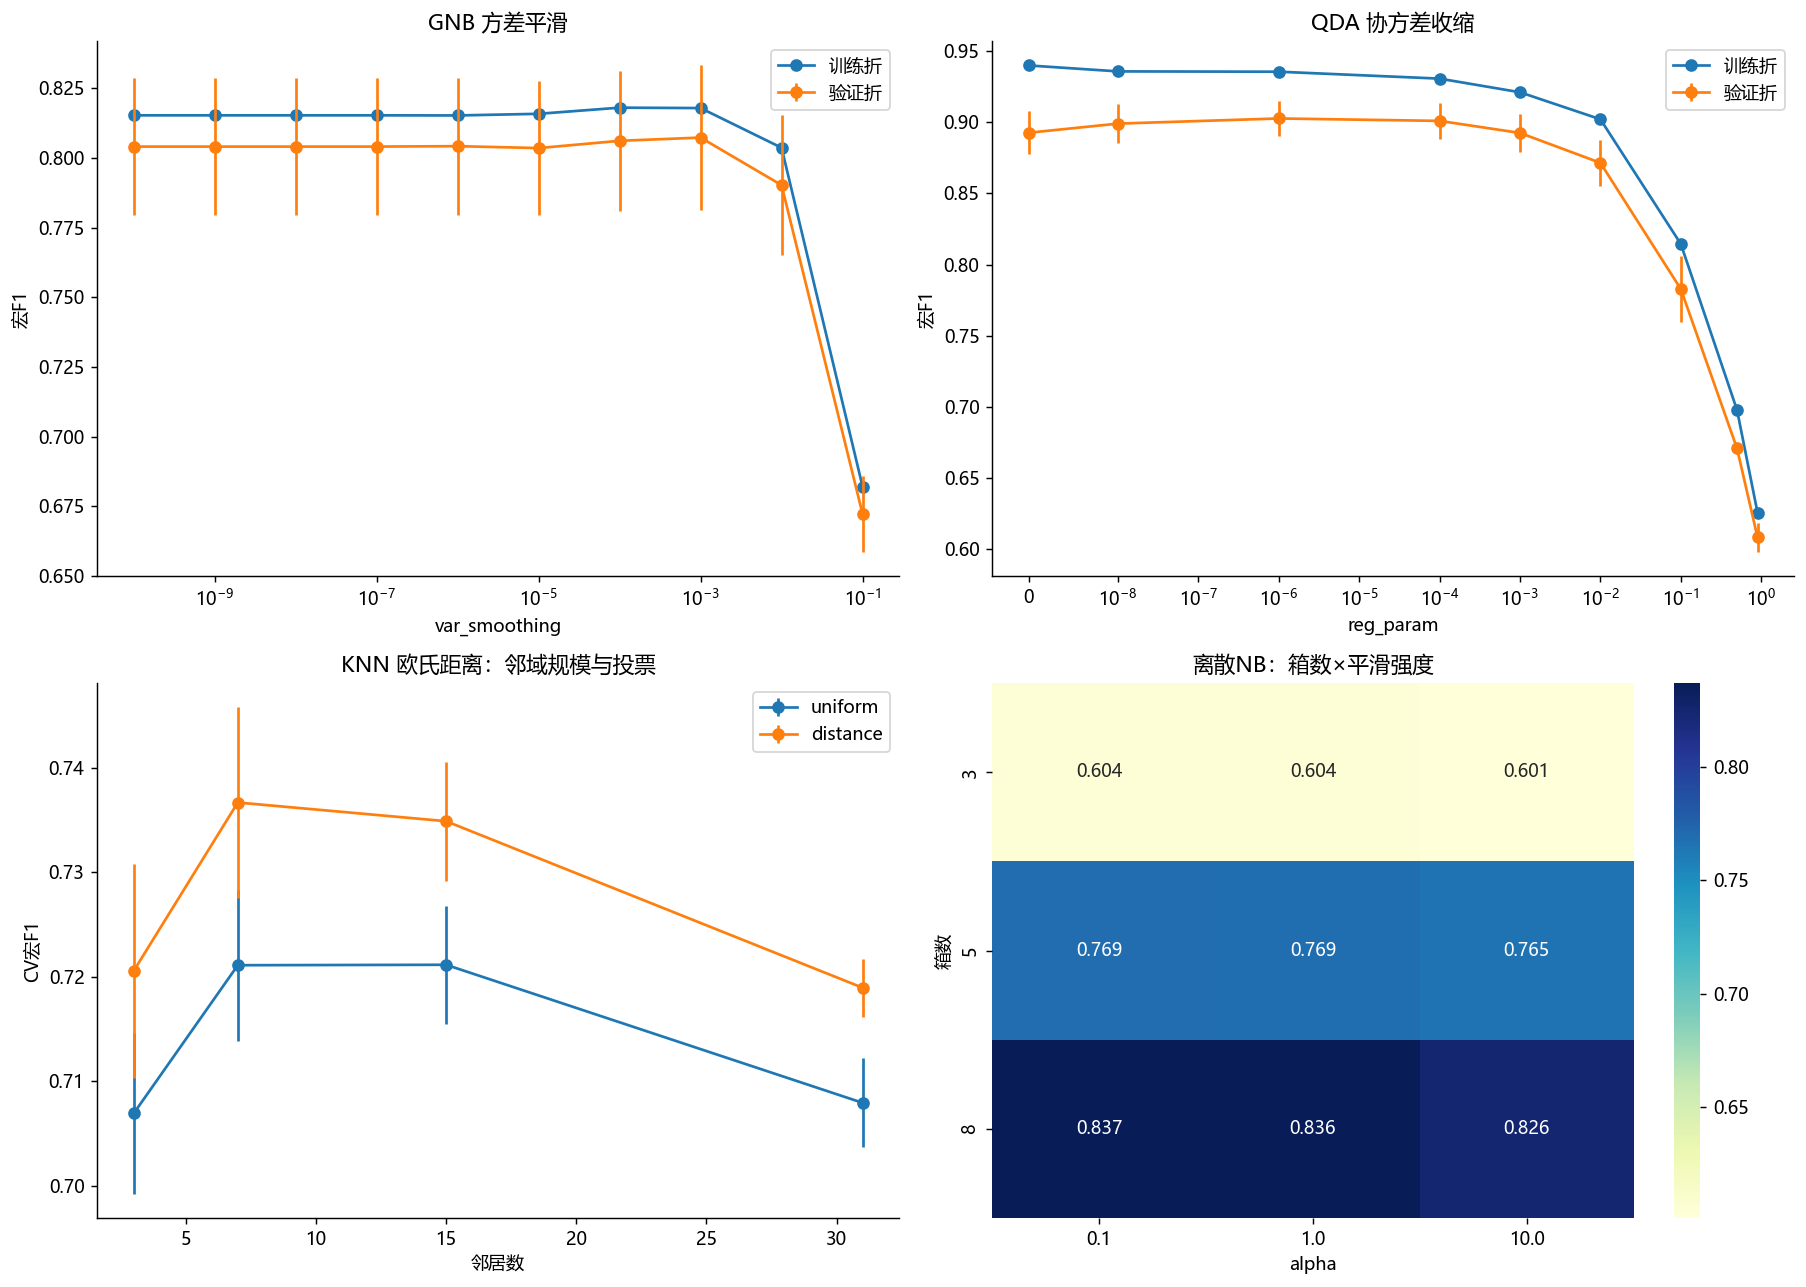

In [15]:
fig,axes=plt.subplots(2,2,figsize=(14,10))
gcv=pd.DataFrame(screen_searches['GaussianNB'].cv_results_)
v=gcv['param_model__var_smoothing'].astype(float)
axes[0,0].semilogx(v,gcv['mean_train_f1_macro'],'o-',label='训练折')
axes[0,0].errorbar(v,gcv['mean_test_f1_macro'],yerr=gcv['std_test_f1_macro'],fmt='o-',label='验证折')
axes[0,0].set(title='GNB 方差平滑',xlabel='var_smoothing',ylabel='宏F1')
axes[0,0].legend()
qcv=pd.DataFrame(screen_searches['QDA'].cv_results_)
v=qcv['param_model__reg_param'].astype(float)
axes[0,1].plot(v,qcv['mean_train_f1_macro'],'o-',label='训练折')
axes[0,1].errorbar(v,qcv['mean_test_f1_macro'],yerr=qcv['std_test_f1_macro'],fmt='o-',label='验证折')
axes[0,1].set(title='QDA 协方差收缩',xlabel='reg_param',ylabel='宏F1')
axes[0,1].legend()
axes[0,1].set_xscale('symlog',linthresh=1e-8)
kcv=pd.DataFrame(screen_searches['KNN'].cv_results_)
for weight in ['uniform','distance']:
    part=kcv[(kcv['param_model__p']==2)&(kcv['param_model__weights']==weight)]
    axes[1,0].errorbar(part['param_model__n_neighbors'].astype(int),part['mean_test_f1_macro'],
                       yerr=part['std_test_f1_macro'],fmt='o-',label=weight)
axes[1,0].set(title='KNN 欧氏距离：邻域规模与投票',xlabel='邻居数',ylabel='CV宏F1')
axes[1,0].legend()
ccv=pd.DataFrame(screen_searches['CategoricalNB'].cv_results_)
pivot=ccv.pivot(index='param_bins__n_bins',columns='param_model__alpha',values='mean_test_f1_macro')
sns.heatmap(pivot.astype(float),annot=True,fmt='.3f',cmap='YlGnBu',ax=axes[1,1])
axes[1,1].set(title='离散NB：箱数×平滑强度',xlabel='alpha',ylabel='箱数')
plt.tight_layout()
show_figure('07_hyperparameter_search_curves')

QDA / 完整训练集验证拟合：捕获11条数值提示，原文与次数见文末数值诊断表。


**完整训练集重拟合后：验证集模型比较**

,模型,版本,训练条数,拟合秒数,参数,Accuracy,Macro F1,Macro Recall,Log Loss,Brier(sum)
0,KNN,调参后,35105,0.04367,"{'model__n_neighbors': 15, 'model__p': 1, 'mod...",0.97889,0.97890,0.97889,0.15791,0.06449
1,CategoricalNB,调参后,35105,0.22925,"{'bins__n_bins': 8, 'model__alpha': 0.1}",0.85336,0.85147,0.85336,0.75110,0.24440
2,LDA,调参后,35105,0.09493,{'model__shrinkage': 0},0.84738,0.84660,0.84737,0.45814,0.23645
3,QDA,调参后,35105,0.21121,{'model__reg_param': 1e-08},0.84883,0.82692,0.84885,1.12581,0.26841
4,GaussianNB,调参后,35105,0.07840,{'model__var_smoothing': np.float64(0.001)},0.72543,0.67235,0.72547,2.42377,0.49404


**优化前对照：量纲处理消融**

,模型,Accuracy,Macro F1,Macro Recall,Log Loss,Brier(sum)
0,GaussianNB原量纲默认,0.74278,0.71637,0.74281,1.83557,0.44971
1,GaussianNB标准化默认,0.71894,0.66573,0.71898,2.63898,0.50599
2,KNN原量纲默认,0.11451,0.10939,0.11450,21.16447,1.06156
3,KNN标准化默认,0.80935,0.80994,0.80933,1.44922,0.27096


按验证集规则选出的全部模型最优： KNN
按同一规则选出的生成模型最优： CategoricalNB


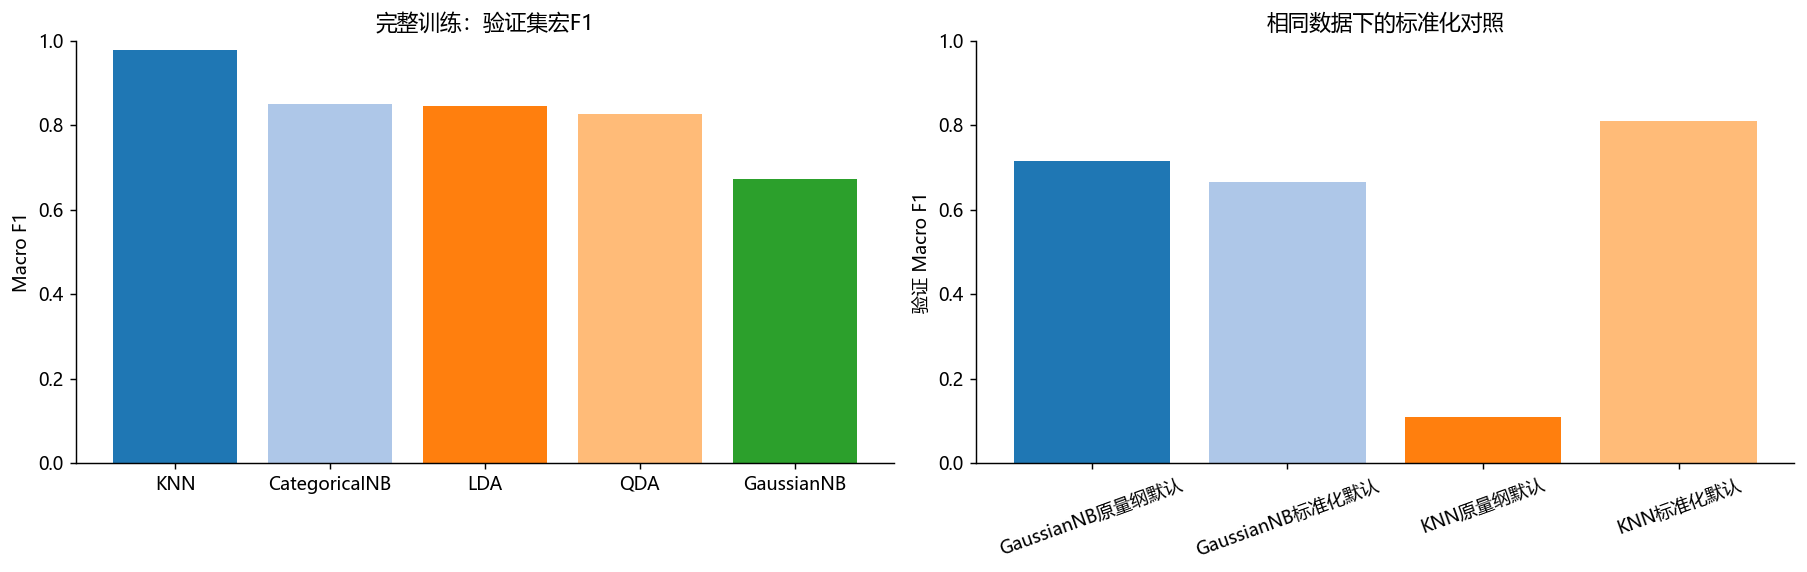

In [16]:
def evaluation_metrics(truth,prob):
    predicted=classes[np.argmax(prob,axis=1)]
    return {'Accuracy':accuracy_score(truth,predicted),
            'Macro F1':f1_score(truth,predicted,average='macro'),
            'Macro Recall':recall_score(truth,predicted,average='macro'),
            'Log Loss':log_loss(truth,prob,labels=classes),
            'Brier(sum)':np.mean(np.sum((prob-(np.asarray(truth)[:,None]==classes[None,:]))**2,axis=1))}

validation_rows=[]
full_train_models={}
validation_probabilities={}
# 所有模型使用完整 35,105 条左右的训练数据，验证集固定不变。
for name,search in searches.items():
    estimator=clone(search.best_estimator_)
    start=time.perf_counter()
    fit_with_diagnostics(estimator,X_train,y_train,name,'完整训练集验证拟合')
    fit_seconds=time.perf_counter()-start
    prob=estimator.predict_proba(X_val)
    validation_probabilities[name]=prob
    full_train_models[name]=estimator
    row={'模型':name,'版本':'调参后','训练条数':len(X_train),'拟合秒数':fit_seconds,
         '参数':str(search.best_params_),**evaluation_metrics(y_val,prob)}
    validation_rows.append(row)

# 优化前对照只作验证集消融展示；最终选模集合使用上面的五个已调参模型。
baselines={
    'GaussianNB原量纲默认':Pipeline([('model',GaussianNB())]),
    'GaussianNB标准化默认':scaled_model(GaussianNB()),
    'KNN原量纲默认':Pipeline([('model',KNeighborsClassifier(algorithm='brute',n_jobs=1))]),
    'KNN标准化默认':scaled_model(KNeighborsClassifier(algorithm='brute',n_jobs=1)),
}
baseline_rows=[]
for name,estimator in baselines.items():
    estimator.fit(X_train,y_train)
    baseline_rows.append({'模型':name,**evaluation_metrics(y_val,estimator.predict_proba(X_val))})
validation_results=pd.DataFrame(validation_rows).sort_values(
    ['Macro F1','Log Loss','模型'],ascending=[False,True,True]).reset_index(drop=True)
baseline_results=pd.DataFrame(baseline_rows)
display(Markdown('**完整训练集重拟合后：验证集模型比较**'))
display(validation_results.round(5))
display(Markdown('**优化前对照：量纲处理消融**'))
display(baseline_results.round(5))
selected_name=validation_results.iloc[0]['模型']
selected_generative=validation_results[validation_results['模型']!='KNN'].iloc[0]['模型']
print('按验证集规则选出的全部模型最优：',selected_name)
print('按同一规则选出的生成模型最优：',selected_generative)

fig,axes=plt.subplots(1,2,figsize=(14,4.5))
axes[0].bar(validation_results['模型'],validation_results['Macro F1'],color=COLORS[:5])
axes[0].set(title='完整训练：验证集宏F1',ylabel='Macro F1',ylim=(0,1))
axes[1].bar(baseline_results['模型'],baseline_results['Macro F1'],color=COLORS[:4])
axes[1].set(title='相同数据下的标准化对照',ylabel='验证 Macro F1',ylim=(0,1))
axes[1].tick_params(axis='x',rotation=20)
plt.tight_layout()
show_figure('08_validation_and_preprocessing_ablation')

### 8.3 训练规模分析

用已选好的 GNB 和 KNN 参数，分别在完整训练集的 10%、30%、60%、100% 的分层样本上拟合，评估同一验证集。该图用于诊断样本量与方法适配性；最终模型族和参数沿用前节既定选择。每个点还记录训练和预测耗时，使统计表现与计算成本同时可见。

,模型,训练样本数,验证宏F1,训练加验证预测秒数
0,GaussianNB,3510,0.8258,0.0820
1,GaussianNB,10531,0.8005,0.1305
2,GaussianNB,21063,0.6971,0.1185
3,GaussianNB,35105,0.6723,0.1427
4,KNN,3510,0.8933,0.8497
5,KNN,10531,0.9517,2.2759
6,KNN,21063,0.9687,4.7653
7,KNN,35105,0.9789,8.4307


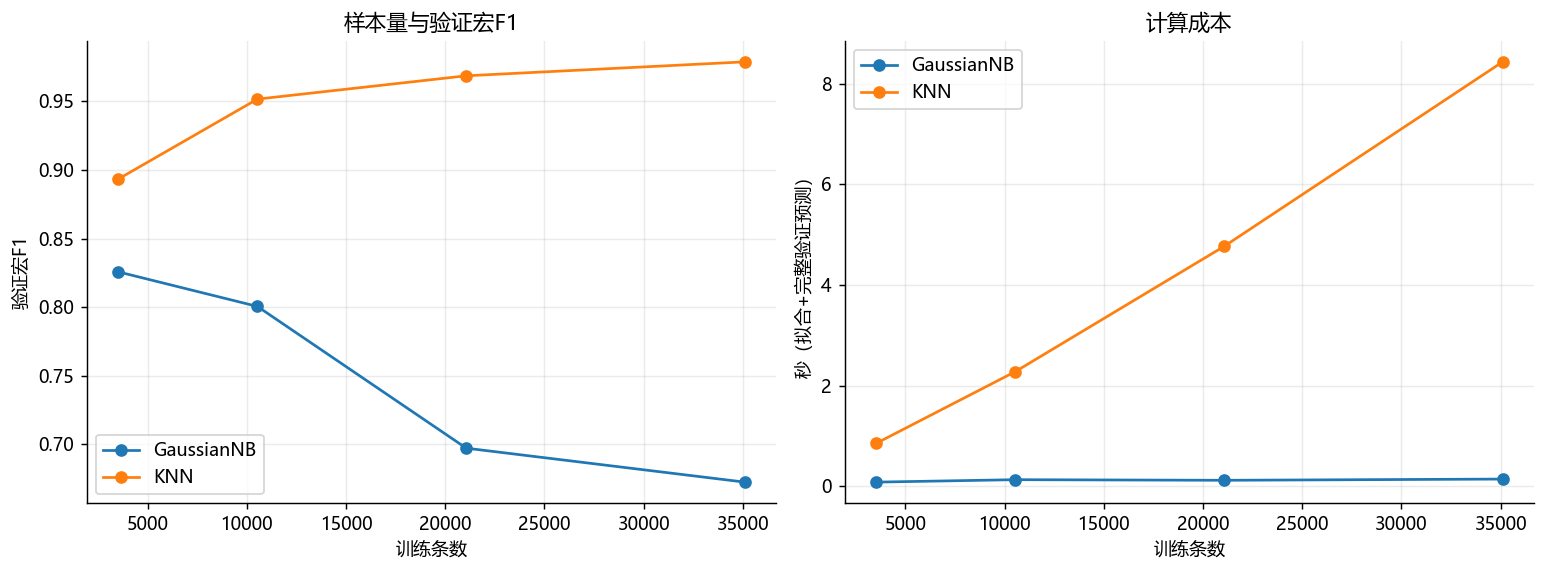

In [17]:
learning_rows=[]
for name in ['GaussianNB','KNN']:
    for fraction in [.1,.3,.6,1.0]:
        if fraction==1.0:
            local=np.arange(len(X_train))
        else:
            local,_=train_test_split(np.arange(len(X_train)),train_size=fraction,
                                     random_state=SEED,stratify=y_train)
        estimator=clone(searches[name].best_estimator_)
        start=time.perf_counter()
        estimator.fit(X_train.iloc[local],y_train.iloc[local])
        prob=estimator.predict_proba(X_val)
        elapsed=time.perf_counter()-start
        learning_rows.append({'模型':name,'训练样本数':len(local),'验证宏F1':evaluation_metrics(y_val,prob)['Macro F1'],
                              '训练加验证预测秒数':elapsed})
learning_results=pd.DataFrame(learning_rows)
display(learning_results.round(4))
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for name in ['GaussianNB','KNN']:
    part=learning_results[learning_results['模型']==name]
    axes[0].plot(part['训练样本数'],part['验证宏F1'],'o-',label=name)
    axes[1].plot(part['训练样本数'],part['训练加验证预测秒数'],'o-',label=name)
axes[0].set(title='样本量与验证宏F1',xlabel='训练条数',ylabel='验证宏F1')
axes[1].set(title='计算成本',xlabel='训练条数',ylabel='秒（拟合+完整验证预测）')
for ax in axes:ax.legend();ax.grid(alpha=.25)
plt.tight_layout()
show_figure('09_training_size_diagnostics')

## 九、测试与分析

### 9.1 分类结果

将训练集与验证集合并，使用锁定的参数重拟合五个候选模型；测试表同时报告各方法，并明确标记在查看测试标签之前选出的最终模型。最终选择沿用验证排序。

类别行号按 C01—C11 排列，混淆矩阵使用“行是真实类别、列是预测类别”。展示最终总体最优和最终生成模型最优：若两者是同一模型，则只绘制一幅，以免重复。逐类 Precision、Recall、F1 与样本数用于定位主要混淆。

QDA / 训练加验证最终拟合：捕获11条数值提示，原文与次数见文末数值诊断表。


,模型,验证已选最终模型,测试条数,训练条数,拟合秒数,测试预测秒数,Accuracy,Macro F1,Macro Recall,Log Loss,Brier(sum)
0,GaussianNB,False,11702,46807,0.11210,0.07511,0.72535,0.66951,0.72539,1.93460,0.48895
1,LDA,False,11702,46807,0.12915,0.00772,0.84712,0.84655,0.84714,0.46850,0.24065
2,QDA,False,11702,46807,0.24037,0.08587,0.84515,0.82516,0.84518,0.90291,0.26767
3,CategoricalNB,False,11702,46807,0.27997,0.04077,0.86037,0.85885,0.86039,0.71229,0.23338
4,KNN,True,11702,46807,0.05213,10.39755,0.98146,0.98148,0.98146,0.13668,0.05563



KNN 逐类报告
              precision    recall  f1-score   support

         C01     0.9799    0.9643    0.9721      1064
         C02     0.9662    0.9671    0.9667      1064
         C03     0.9944    0.9991    0.9967      1063
         C04     0.9887    0.9868    0.9878      1064
         C05     0.9765    0.9784    0.9775      1064
         C06     0.9434    0.9709    0.9569      1064
         C07     1.0000    1.0000    1.0000      1064
         C08     0.9868    0.9850    0.9859      1064
         C09     0.9914    0.9756    0.9834      1064
         C10     0.9699    0.9690    0.9694      1064
         C11     1.0000    1.0000    1.0000      1063

    accuracy                         0.9815     11702
   macro avg     0.9816    0.9815    0.9815     11702
weighted avg     0.9816    0.9815    0.9815     11702


CategoricalNB 逐类报告


              precision    recall  f1-score   support

         C01     0.8742    0.8882    0.8811      1064
         C02     0.8872    0.7538    0.8150      1064
         C03     0.8868    0.9727    0.9278      1063
         C04     0.7672    0.7773    0.7722      1064
         C05     0.8007    0.6795    0.7351      1064
         C06     0.7808    0.7867    0.7837      1064
         C07     0.9637    0.9991    0.9811      1064
         C08     0.8649    0.8722    0.8685      1064
         C09     0.8312    0.8468    0.8389      1064
         C10     0.8056    0.8882    0.8449      1064
         C11     0.9981    1.0000    0.9991      1063

    accuracy                         0.8604     11702
   macro avg     0.8600    0.8604    0.8589     11702
weighted avg     0.8600    0.8604    0.8588     11702



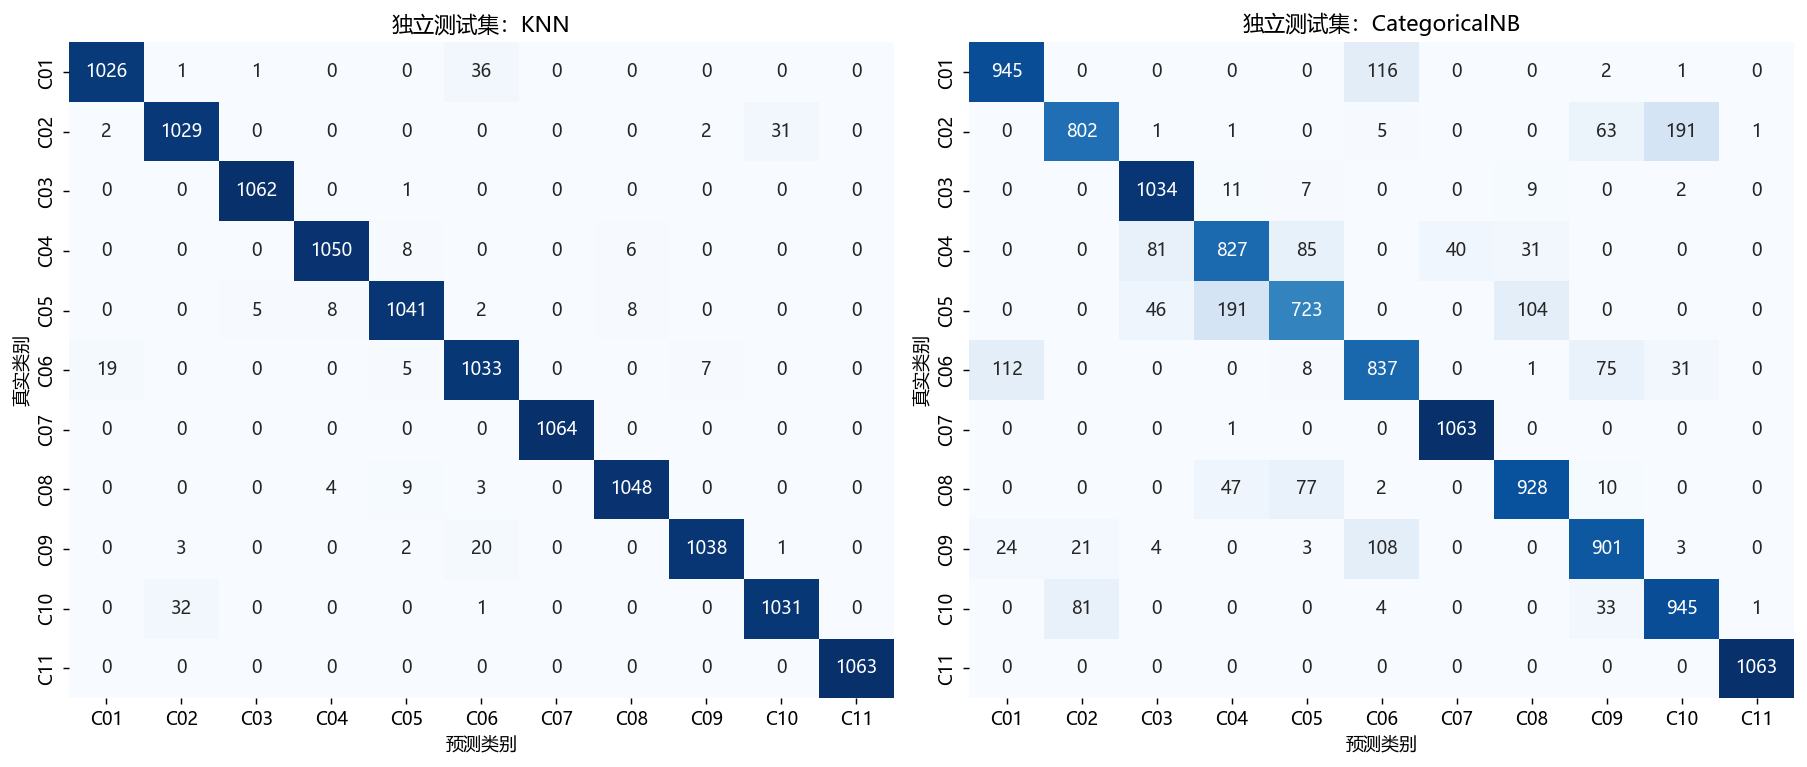

In [18]:
X_development=X.iloc[trainval_idx]
y_development=y.iloc[trainval_idx]
test_rows=[]
final_models={}
test_probabilities={}
for name,search in searches.items():
    estimator=clone(search.best_estimator_)
    start=time.perf_counter()
    fit_with_diagnostics(estimator,X_development,y_development,name,'训练加验证最终拟合')
    fit_seconds=time.perf_counter()-start
    start=time.perf_counter()
    prob=estimator.predict_proba(X_test)
    predict_seconds=time.perf_counter()-start
    final_models[name]=estimator
    test_probabilities[name]=prob
    test_rows.append({'模型':name,'验证已选最终模型':name==selected_name,
                      '测试条数':len(X_test),'训练条数':len(X_development),
                      '拟合秒数':fit_seconds,'测试预测秒数':predict_seconds,
                      **evaluation_metrics(y_test,prob)})
test_results=pd.DataFrame(test_rows)
display(test_results.round(5))

report_names=list(dict.fromkeys([selected_name,selected_generative]))
fig,axes=plt.subplots(1,len(report_names),figsize=(7*len(report_names),6),squeeze=False)
for ax,name in zip(axes.ravel(),report_names):
    prediction=classes[test_probabilities[name].argmax(axis=1)]
    matrix=confusion_matrix(y_test,prediction,labels=classes)
    sns.heatmap(matrix,annot=True,fmt='d',cmap='Blues',cbar=False,
                xticklabels=class_names,yticklabels=class_names,ax=ax)
    ax.set(title=f'独立测试集：{name}',xlabel='预测类别',ylabel='真实类别')
    print(f'\n{name} 逐类报告')
    print(classification_report(y_test,prediction,labels=classes,target_names=class_names,digits=4))
plt.tight_layout()
show_figure('10_test_confusion_matrices')

### 9.2 后验概率评估

模型的最大后验 $q_i=\max_k\gamma_k(x_i)$ 是该条分类的置信度。将置信度分组，比较每组平均置信度与实际正确率，得到 top-label 可靠性图。分组越接近对角线，置信度与正确率越吻合。每个箱同时报告样本数，以展示经验估计所依据的信息量。

高斯条件独立模型将各特征信息相乘；强条件相关会影响后验集中程度。参数收缩、改变协方差结构与概率校准处理的是不同环节。本节报告模型原始后验的 Brier、交叉熵和可靠性形态，量化其概率质量。

**GaussianNB 可靠性分箱：平均置信度、正确率与样本数**

,mean_confidence,accuracy,n
bin,,,
3,0.368451,0.263158,19
4,0.458242,0.395833,96
5,0.551666,0.400000,280
6,0.652701,0.378840,293
7,0.754104,0.316527,357
8,0.855179,0.363458,509
9,0.994189,0.780844,10148


GaussianNB 测试多类Brier= 0.4889521662406426 平均后验熵= 0.10753914282320189


**CategoricalNB 可靠性分箱：平均置信度、正确率与样本数**

,mean_confidence,accuracy,n
bin,,,
3,0.374540,0.666667,6
4,0.466156,0.370370,54
5,0.546893,0.504505,333
6,0.650297,0.551155,303
7,0.752286,0.564171,374
8,0.854193,0.605787,553
9,0.993386,0.909118,10079


CategoricalNB 测试多类Brier= 0.23337675283151071 平均后验熵= 0.10927015446217542


**KNN 可靠性分箱：平均置信度、正确率与样本数**

,mean_confidence,accuracy,n
bin,,,
2,0.269949,0.437500,16
3,0.360733,0.500000,54
4,0.456229,0.778378,185
5,0.550642,0.767705,353
6,0.652579,0.950796,691
7,0.750691,0.977573,758
8,0.849081,0.998310,1775
9,0.985537,0.999492,7870


KNN 测试多类Brier= 0.055627128584839085 平均后验熵= 0.24993435069711623


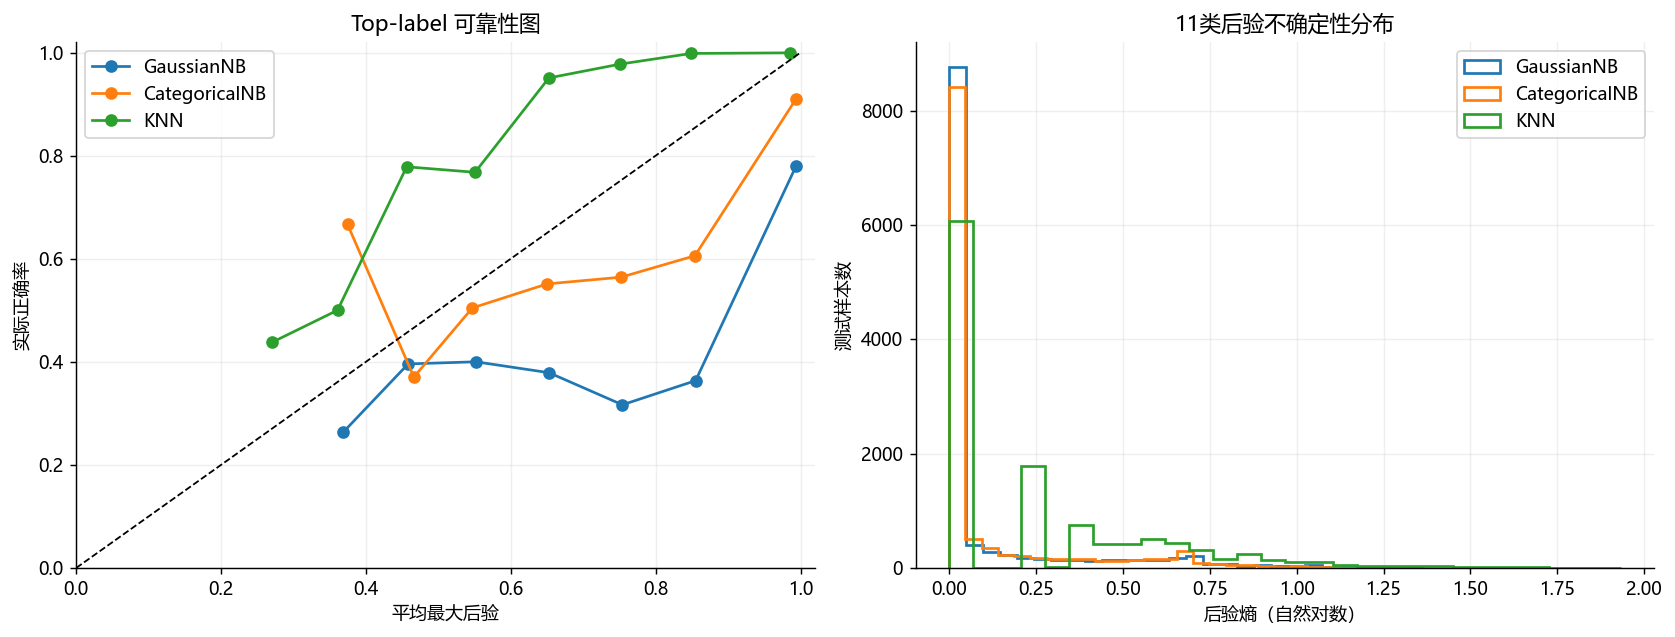

In [19]:
reliability_rows=[]
fig,axes=plt.subplots(1,2,figsize=(13,5))
for name in ['GaussianNB',selected_generative,'KNN']:
    if name in [row.get('done') for row in reliability_rows]:continue
    prob=test_probabilities[name]
    confidence=prob.max(axis=1)
    correct=(classes[prob.argmax(axis=1)]==y_test.to_numpy()).astype(float)
    bin_id=np.minimum((confidence*10).astype(int),9)
    frame=pd.DataFrame({'confidence':confidence,'correct':correct,'bin':bin_id})
    grouped=frame.groupby('bin').agg(mean_confidence=('confidence','mean'),
                                     accuracy=('correct','mean'),n=('correct','size'))
    axes[0].plot(grouped['mean_confidence'],grouped['accuracy'],'o-',label=name)
    reliability_rows.append({'done':name})
    display(Markdown(f'**{name} 可靠性分箱：平均置信度、正确率与样本数**'))
    display(grouped)
    entropy=-np.sum(prob*np.log(np.maximum(prob,1e-300)),axis=1)
    axes[1].hist(entropy,bins=28,histtype='step',linewidth=1.5,label=name)
    print(name,'测试多类Brier=',evaluation_metrics(y_test,prob)['Brier(sum)'],
          '平均后验熵=',entropy.mean())
axes[0].plot([0,1],[0,1],'k--',lw=1)
axes[0].set(xlabel='平均最大后验',ylabel='实际正确率',title='Top-label 可靠性图',xlim=(0,1.02),ylim=(0,1.02))
axes[1].set(xlabel='后验熵（自然对数）',ylabel='测试样本数',title='11类后验不确定性分布')
for ax in axes:ax.legend();ax.grid(alpha=.2)
plt.tight_layout()
show_figure('11_test_probability_reliability_entropy')

### 9.3 ROC、KS 与提升曲线

预先固定 C01 为正类、其余类别为负类，用最终总体模型给 C01 的后验概率排序。ROC AUC 对应 C01 与其余类的区分；$KS=\max_t|TPR(t)-FPR(t)|$；前 $q$ 比例样本的累积增益为已捕获 C01 占全部 C01 的比例，累积提升为增益除以 $q$。相同分数先聚合到阈值组，保证 KS 与 ROC 的处理一致。排序图用来说明第 68—79 页指标，主任务仍是 11 类宏 F1。

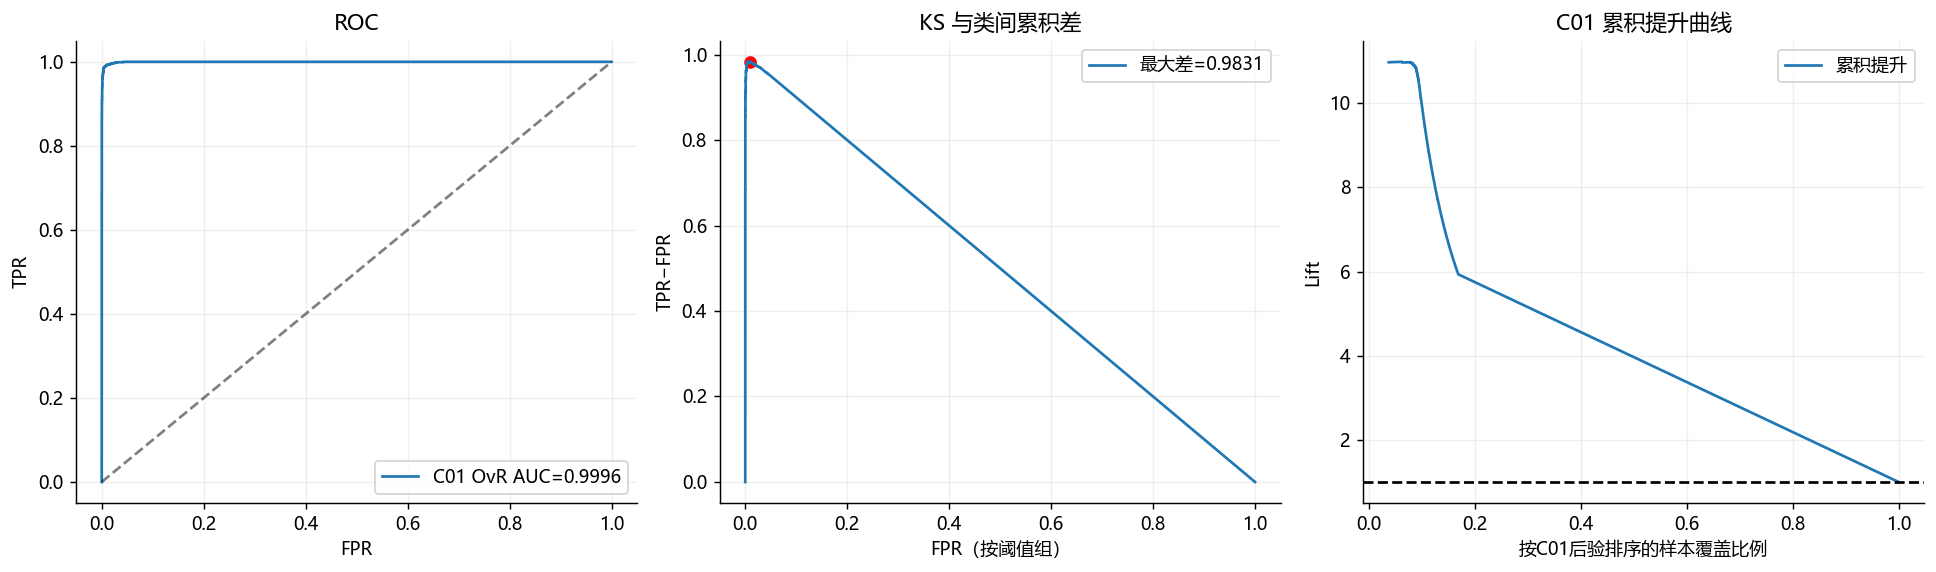

C01 正类样本=1064；ROC AUC=0.999566；KS=0.983081；Gini=2*AUC-1=0.999133


In [20]:
positive=(y_test.to_numpy()==1).astype(int)
rank_score=test_probabilities[selected_name][:,0]
fpr,tpr,thresholds=roc_curve(positive,rank_score)
ks_index=int(np.argmax(np.abs(tpr-fpr)))
ks=float(abs(tpr[ks_index]-fpr[ks_index]))
auc=roc_auc_score(positive,rank_score)
rank_groups=pd.DataFrame({'score':rank_score,'positive':positive}).groupby('score').agg(
    n=('positive','size'),positives=('positive','sum')).sort_index(ascending=False)
depth=rank_groups['n'].cumsum().to_numpy()/len(positive)
gain=rank_groups['positives'].cumsum().to_numpy()/positive.sum()
lift=gain/depth
fig,axes=plt.subplots(1,3,figsize=(15,4.5))
axes[0].plot(fpr,tpr,label=f'C01 OvR AUC={auc:.4f}')
axes[0].plot([0,1],[0,1],'k--',alpha=.5)
axes[0].set(xlabel='FPR',ylabel='TPR',title='ROC')
axes[1].plot(fpr,tpr-fpr,label=f'最大差={ks:.4f}')
axes[1].scatter(fpr[ks_index],tpr[ks_index]-fpr[ks_index],color='red')
axes[1].set(xlabel='FPR（按阈值组）',ylabel='TPR−FPR',title='KS 与类间累积差')
axes[2].plot(depth,lift,label='累积提升')
axes[2].axhline(1,color='black',linestyle='--')
axes[2].set(xlabel='按C01后验排序的样本覆盖比例',ylabel='Lift',title='C01 累积提升曲线')
for ax in axes:ax.legend();ax.grid(alpha=.2)
plt.tight_layout()
show_figure('12_one_vs_rest_roc_ks_lift')
print(f'C01 正类样本={positive.sum()}；ROC AUC={auc:.6f}；KS={ks:.6f}；Gini=2*AUC-1={2*auc-1:.6f}')

### 9.4 错分分析

对验证集已选出的最终模型和最优生成模型，列出测试集中最多的五个有向误判对，并给出真实类中的误判比例。随后固定一条 GNB 错分、KNN 正确的记录（按测试集原排列取第一条），比较五个模型对全部 11 类的后验。若该集合为空，则按测试集顺序取第一条 GNB 错分记录。这是模型锁定后的误差解释步骤。

概率和为 1 来自贝叶斯归一化；后验的实证质量通过真实类概率、Log Loss、Brier 和可靠性图评价。对同一条记录同时阅读预测类别、最大后验和真实类后验，可以把分类决策与概率质量对应起来。

,模型,真实类,预测类,误判条数,占真实类比例
0,KNN,C01,C06,36,0.033835
1,KNN,C10,C02,32,0.030075
2,KNN,C02,C10,31,0.029135
3,KNN,C09,C06,20,0.018797
4,KNN,C06,C01,19,0.017857
5,CategoricalNB,C05,C04,191,0.179511
6,CategoricalNB,C02,C10,191,0.179511
7,CategoricalNB,C01,C06,116,0.109023
8,CategoricalNB,C06,C01,112,0.105263
9,CategoricalNB,C09,C06,108,0.101504


,C01,C02,C03,C04,C05,C06,C07,C08,C09,C10,C11
GaussianNB,5.5172e-38,3.6311e-32,1,1.9634e-08,9.7028e-15,1.5325e-23,2.9188e-40,2.5925e-18,1.3291e-17,8.113e-30,4.4795e-44
LDA,1.2514e-05,1.0171e-05,0.97315,0.00046327,0.022929,0.0019821,2.1426e-24,0.00069686,0.00044098,0.00031452,6.7054e-98
QDA,6.3871e-41,2.1879e-19,4.2031e-07,1,9.465e-10,8.5857e-27,1.0992e-105,1.9345e-20,1.2519e-09,1.3327e-20,2.4693e-138
CategoricalNB,1.5527e-23,1.2287e-16,0.99999,8.603e-06,1.1176e-07,1.7426e-23,5.0277e-21,1.6401e-13,1.1897e-11,1.3456e-41,1.4822e-30
KNN,0,0,0,1,0,0,0,0,0,0,0


,模型,预测,最大后验,真实类后验
0,GaussianNB,C03,1.000000,1.963395e-08
1,LDA,C03,0.973151,4.632682e-04
2,QDA,C04,1.000000,9.999996e-01
3,CategoricalNB,C03,0.999991,8.603041e-06
4,KNN,C04,1.000000,1.000000e+00


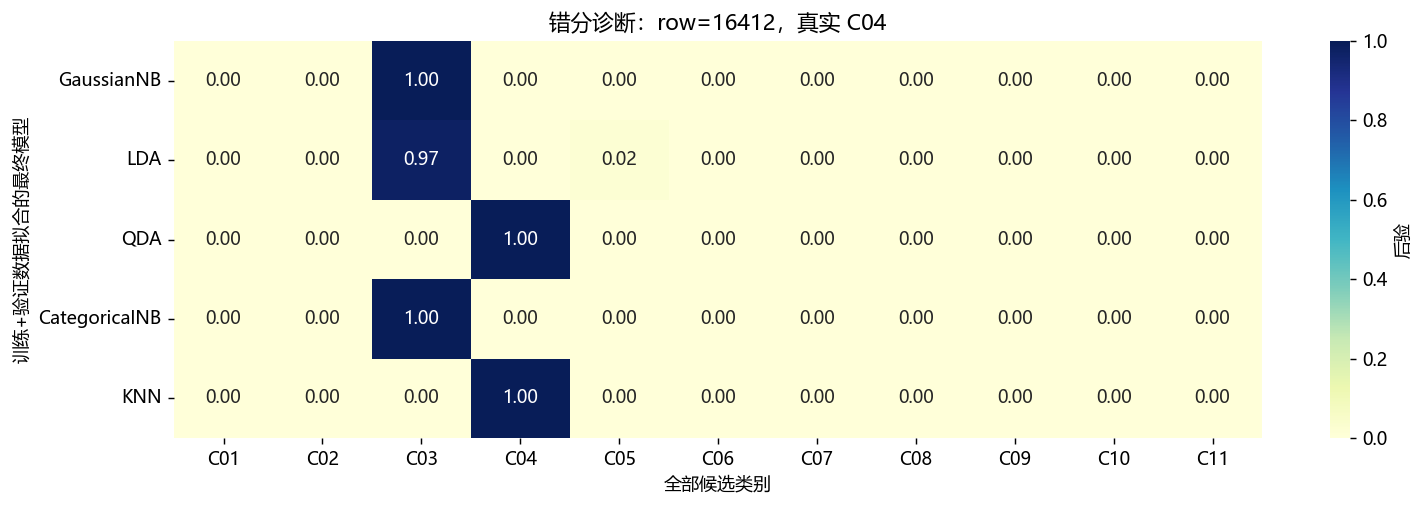

In [21]:
error_pair_rows=[]
for name in report_names:
    predictions=classes[test_probabilities[name].argmax(axis=1)]
    cm=confusion_matrix(y_test,predictions,labels=classes)
    pairs=[(int(cm[a,b]),a,b) for a in range(K) for b in range(K) if a!=b and cm[a,b]>0]
    for count,true_position,predicted_position in sorted(pairs,reverse=True)[:5]:
        error_pair_rows.append({'模型':name,'真实类':class_names[true_position],
                                '预测类':class_names[predicted_position],
                                '误判条数':count,'占真实类比例':count/cm[true_position].sum()})
error_pairs=pd.DataFrame(error_pair_rows)
display(error_pairs)
gnb_prediction=classes[test_probabilities['GaussianNB'].argmax(axis=1)]
knn_prediction=classes[test_probabilities['KNN'].argmax(axis=1)]
wrong_positions=np.flatnonzero((gnb_prediction!=y_test.to_numpy())&(knn_prediction==y_test.to_numpy()))
if not len(wrong_positions):
    wrong_positions=np.flatnonzero(gnb_prediction!=y_test.to_numpy())
if len(wrong_positions):
    error_position=int(wrong_positions[0])
    true_class=int(y_test.iloc[error_position])
    posterior_comparison=pd.DataFrame({name:prob[error_position] for name,prob in test_probabilities.items()},
                                      index=class_names).T
    display(posterior_comparison.style.format('{:.5g}'))
    error_summary=[]
    for name,prob in test_probabilities.items():
        p=prob[error_position]
        error_summary.append({'模型':name,'预测':class_names[p.argmax()],
                              '最大后验':p.max(),'真实类后验':p[true_class-1]})
    display(pd.DataFrame(error_summary))
    fig,ax=plt.subplots(figsize=(12,4))
    sns.heatmap(posterior_comparison,annot=True,fmt='.2f',vmin=0,vmax=1,cmap='YlGnBu',ax=ax,
                cbar_kws={'label':'后验'})
    ax.set(title=f'错分诊断：row={X_test.index[error_position]}，真实 C{true_class:02d}',
           xlabel='全部候选类别',ylabel='训练+验证数据拟合的最终模型')
    plt.tight_layout()
    show_figure('14_error_record_all_class_probabilities')

## 十、结论

本作业建立了两条完整的概率计算链。连续特征链从高斯联合似然推导先验、均值和协方差，再从条件独立得到 48 个一维密度的乘积，使用对数联合密度和证据归一化得到每类后验。离散特征链从训练箱计数出发，结合 Dirichlet 后验预测完成拉普拉斯平滑，然后对真实 48 维观测逐类归一化。两条链都逐一核对全部 11 类。

模型优化把统计结构与数值实现连接起来：标准化改变计算尺度；GNB 平滑限制小方差尖峰；LDA 共享协方差减少估计自由度；QDA 保留类别特异的相关结构；离散 NB 用箱数与伪计数控制概率分辨率；KNN 用距离、邻居数和权重决定局部投票。下方根据本次实际运行结果生成最终报告，选模依据固定为验证集排序。

In [22]:
selected_val=validation_results[validation_results['模型']==selected_name].iloc[0]
selected_test=test_results[test_results['模型']==selected_name].iloc[0]
gen_val=validation_results[validation_results['模型']==selected_generative].iloc[0]
gen_test=test_results[test_results['模型']==selected_generative].iloc[0]
display(Markdown(
    f'**验证集选择结果：** 总体最终模型为 **{selected_name}**，验证宏F1={selected_val["Macro F1"]:.4f}；'
    f'生成模型中最优为 **{selected_generative}**，验证宏F1={gen_val["Macro F1"]:.4f}。\n\n'
    f'**独立测试：** {selected_name} 的 Accuracy={selected_test["Accuracy"]:.4f}、'
    f'宏F1={selected_test["Macro F1"]:.4f}、Log Loss={selected_test["Log Loss"]:.4f}；'
    f'{selected_generative} 的测试宏F1={gen_test["Macro F1"]:.4f}。\n\n'
    f'**复算核验：** GNB 手工均值、方差与后验、离散NB真实箱计数后验、KNN距离投票均通过数值一致性检查。'
))

base_index=baseline_results.set_index('模型')
val_index=validation_results.set_index('模型')
raw_knn=base_index.loc['KNN原量纲默认','Macro F1']
scaled_knn=base_index.loc['KNN标准化默认','Macro F1']
tuned_knn=val_index.loc['KNN','Macro F1']
default_gnb=base_index.loc['GaussianNB标准化默认','Macro F1']
tuned_gnb=val_index.loc['GaussianNB','Macro F1']
knn_learning=learning_results[learning_results['模型']=='KNN']
gnb_learning=learning_results[learning_results['模型']=='GaussianNB']
display(Markdown(
    f'**1. 预处理和参数分别贡献什么。** 相同验证集上，默认 KNN 从原量纲宏F1={raw_knn:.4f}'
    f'变为标准化后的 {scaled_knn:.4f}，再经距离、邻居数和权重选择达到 {tuned_knn:.4f}。'
    f'标准化让不同量纲共同进入距离；参数搜索进一步改变局部邻域及投票。'
    f'GNB 在标准化默认参数下为 {default_gnb:.4f}，优化后为 {tuned_gnb:.4f}。'
    '理想高斯模型在一致可逆尺度变换下保持后验，实际 GaussianNB 的全局加性平滑随坐标尺度改变，'
    '因此标准化与平滑要联合考察。\n\n'
    f'**2. 协方差结构为什么值得比较。** 本数据 {features[pair[0]]} 与 {features[pair[1]]} 的平均类内绝对相关为 '
    f'{mean_abs_corr[pair[0],pair[1]]:.9f}。对角模型用两个边际的乘积，共享协方差模型保留统一相关结构，'
    'QDA 为每一类估计自己的方向与尺度。曲面、椭圆、类内相关热图和谱条件数展示了这些约束的统计及数值后果。'
    f'最优生成模型 {selected_generative} 的验证宏F1={gen_val["Macro F1"]:.4f}，'
    f'对应 GNB 为 {tuned_gnb:.4f}；两者的模型结构与调节参数均已列明。\n\n'
    f'**3. 样本量和模型假设怎样共同作用。** KNN 从 {int(knn_learning.iloc[0]["训练样本数"])} 条训练记录的'
    f'验证宏F1={knn_learning.iloc[0]["验证宏F1"]:.4f}，变化至完整训练集的 '
    f'{knn_learning.iloc[-1]["验证宏F1"]:.4f}。GNB 四个训练规模的宏F1范围为 '
    f'{gnb_learning["验证宏F1"].min():.4f}—{gnb_learning["验证宏F1"].max():.4f}。'
    '高斯边际诊断提供分布形状的依据：类内尾部和尖峰会进入均值、方差估计；'
    '模型对样本量的响应由估计波动和分布假设一起决定。训练规模曲线直接记录本数据上的变化。\n\n'
    '**4. 分类与概率分别怎样评价。** 宏F1评价逐类分类结果；Log Loss关心真实类别被赋予的概率，'
    'Brier衡量整条概率向量的平方误差。可靠性图和错分记录展示这些指标的来源。'
    '本研究以宏F1为预先确定的主要选择指标，其余指标用于说明最终模型的概率表现和应用取舍。'
))

parameter_changes=[]
for name in searches:
    parameter_changes.append({'模型':name,'12000条初筛参数':str(screen_searches[name].best_params_),
                              '完整训练集精筛参数':str(searches[name].best_params_)})
with pd.option_context('display.max_colwidth',None):
    display(pd.DataFrame(parameter_changes))
manifest={
    'seed':SEED,'dataset_rows':len(data),'features':d,'classes':K,
    'train_rows':len(X_train),'validation_rows':len(X_val),'test_rows':len(X_test),'tuning_rows':len(X_tune),
    'selected_model_by_validation':selected_name,'selected_generative_by_validation':selected_generative,
    'best_params':{name:search.best_params_ for name,search in searches.items()},
    'cv_initial_combinations':sum(len(s.cv_results_['params']) for s in screen_searches.values()),
    'cv_refined_combinations':sum(len(s.cv_results_['params']) for s in searches.values()),
    'data_sha256':hashlib.sha256(DATA_PATH.read_bytes()).hexdigest(),
    'versions':{'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,
                'scipy':scipy.__version__,'sklearn':sklearn.__version__},
}
print('复现环境：',manifest['versions'])
display(Markdown('完整参数、调参记录和数值诊断均直接列于本 notebook；图表与模型比较结果已嵌入对应章节。'))
show_table_details(pd.DataFrame(warning_records), '展开数值诊断：提示原文、阶段与次数')

**验证集选择结果：** 总体最终模型为 **KNN**，验证宏F1=0.9789；生成模型中最优为 **CategoricalNB**，验证宏F1=0.8515。

**独立测试：** KNN 的 Accuracy=0.9815、宏F1=0.9815、Log Loss=0.1367；CategoricalNB 的测试宏F1=0.8589。

**复算核验：** GNB 手工均值、方差与后验、离散NB真实箱计数后验、KNN距离投票均通过数值一致性检查。

**1. 预处理和参数分别贡献什么。** 相同验证集上，默认 KNN 从原量纲宏F1=0.1094变为标准化后的 0.8099，再经距离、邻居数和权重选择达到 0.9789。标准化让不同量纲共同进入距离；参数搜索进一步改变局部邻域及投票。GNB 在标准化默认参数下为 0.6657，优化后为 0.6723。理想高斯模型在一致可逆尺度变换下保持后验，实际 GaussianNB 的全局加性平滑随坐标尺度改变，因此标准化与平滑要联合考察。

**2. 协方差结构为什么值得比较。** 本数据 F22 与 F23 的平均类内绝对相关为 0.999999985。对角模型用两个边际的乘积，共享协方差模型保留统一相关结构，QDA 为每一类估计自己的方向与尺度。曲面、椭圆、类内相关热图和谱条件数展示了这些约束的统计及数值后果。最优生成模型 CategoricalNB 的验证宏F1=0.8515，对应 GNB 为 0.6723；两者的模型结构与调节参数均已列明。

**3. 样本量和模型假设怎样共同作用。** KNN 从 3510 条训练记录的验证宏F1=0.8933，变化至完整训练集的 0.9789。GNB 四个训练规模的宏F1范围为 0.6723—0.8258。高斯边际诊断提供分布形状的依据：类内尾部和尖峰会进入均值、方差估计；模型对样本量的响应由估计波动和分布假设一起决定。训练规模曲线直接记录本数据上的变化。

**4. 分类与概率分别怎样评价。** 宏F1评价逐类分类结果；Log Loss关心真实类别被赋予的概率，Brier衡量整条概率向量的平方误差。可靠性图和错分记录展示这些指标的来源。本研究以宏F1为预先确定的主要选择指标，其余指标用于说明最终模型的概率表现和应用取舍。

,模型,12000条初筛参数,完整训练集精筛参数
0,GaussianNB,{'model__var_smoothing': np.float64(0.001)},{'model__var_smoothing': np.float64(0.001)}
1,LDA,{'model__shrinkage': 0},{'model__shrinkage': 0}
2,QDA,{'model__reg_param': 1e-06},{'model__reg_param': 1e-08}
3,CategoricalNB,"{'bins__n_bins': 8, 'model__alpha': 0.1}","{'bins__n_bins': 8, 'model__alpha': 0.1}"
4,KNN,"{'model__n_neighbors': 7, 'model__p': 1, 'model__weights': 'distance'}","{'model__n_neighbors': 15, 'model__p': 1, 'model__weights': 'distance'}"


复现环境： {'python': '3.13.7', 'numpy': '2.3.2', 'pandas': '2.3.2', 'scipy': '1.16.1', 'sklearn': '1.7.2'}


完整参数、调参记录和数值诊断均直接列于本 notebook；图表与模型比较结果已嵌入对应章节。

model,phase,category,message,count
QDA,12000条初筛,LinAlgWarning,The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.,10
QDA,12000条初筛,LinAlgWarning,The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.,10
QDA,12000条初筛,LinAlgWarning,The covariance matrix of class 2 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.,10
QDA,12000条初筛,LinAlgWarning,The covariance matrix of class 3 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.,10
QDA,12000条初筛,LinAlgWarning,The covariance matrix of class 4 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.,10
QDA,12000条初筛,LinAlgWarning,The covariance matrix of class 5 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.,10
QDA,12000条初筛,LinAlgWarning,The covariance matrix of class 6 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.,10
QDA,12000条初筛,LinAlgWarning,The covariance matrix of class 7 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.,10
QDA,12000条初筛,LinAlgWarning,The covariance matrix of class 8 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.,10
QDA,12000条初筛,LinAlgWarning,The covariance matrix of class 9 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.,10
